# Digitdeck - Entregable M4 

**La pregunta que necesita ojos:** un comprador tiene un producto en la mano, o una foto de él, y no sabe cómo se llama exactamente: *"¿Tienen este celular?"* + foto.


## 0. Entorno de trabajo

In [1]:
%pip install -q sentence-transformers chromadb rank_bm25 openpyxl
print("\nListo.")

Note: you may need to restart the kernel to use updated packages.

Listo.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: C:\Users\sebas\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import importlib.metadata as meta
import os, sys, re, json, time, random, gc, hashlib, html
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

SEMILLA = 42

def fijar_semilla(seed: int = SEMILLA):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

fijar_semilla(SEMILLA)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("=== Entorno de M4 ===")
print(f"Python      : {sys.version.split()[0]}")
print(f"Dispositivo : {DEVICE}" + (f" | {torch.cuda.get_device_name(0)}" if DEVICE == "cuda" else " [AVISO: sin GPU]"))
for pkg in ["torch", "transformers", "sentence_transformers", "chromadb", "rank_bm25", "pandas"]:
    try:
        print(f"  {pkg:<22} {meta.version(pkg)}")
    except meta.PackageNotFoundError:
        print(f"  {pkg:<22} FALTA")

=== Entorno de M4 ===
Python      : 3.11.9
Dispositivo : cuda | NVIDIA GeForce RTX 5060 Ti
  torch                  2.11.0+cu128
  transformers           4.57.1
  sentence_transformers  5.1.2
  chromadb               1.5.9
  rank_bm25              0.2.2
  pandas                 2.3.2


In [3]:
import io, subprocess
from PIL import Image
import matplotlib.pyplot as plt

### 0.1 Rutas, Colab y el modelo de M1



In [ ]:
EN_COLAB = "google.colab" in sys.modules
REPO_GITHUB = "https://github.com/AlejandroSPosada/Topicos_IA_Proyecto_Digitdeck.git"
REPO_MODELO_M1 = "scastanoa1/digitdeck-m1-e5-small-esci-es"   # repo_id del reranker de M1 en el Hub

if EN_COLAB and not Path("/content/repo").exists():
    from getpass import getpass
    _tok = getpass("Token de GitHub con permiso de lectura del repo: ")
    subprocess.run(["git", "clone", "--depth", "1", REPO_GITHUB.replace("https://", f"https://{_tok}@"), "/content/repo"], check=True)
    del _tok
if EN_COLAB:
    os.chdir("/content/repo/Entregables/M4/pipeline")

AQUI = Path.cwd()                                    
RAIZ_M4 = AQUI.parent if AQUI.name == "pipeline" else AQUI   
RAIZ_M3 = (RAIZ_M4 / ".." / "M3").resolve()
RAIZ_M2 = (RAIZ_M4 / ".." / "M2").resolve()
RAIZ_M1 = (RAIZ_M4 / ".." / "M1").resolve()
DIR_RES = RAIZ_M4 / "Resultados"
DIR_VAL = RAIZ_M4 / "Validacion"
DIR_EVAL = RAIZ_M4 / "eval_set"
DIR_IMAGENES = DIR_EVAL / "imagenes"
DIR_INDICES = RAIZ_M4 / "indices"                     
for d in (DIR_RES, DIR_VAL, DIR_INDICES):
    d.mkdir(exist_ok=True)

DIR_ESCI = RAIZ_M1
if not (DIR_ESCI / "shopping_queries_dataset_products.parquet").exists() and EN_COLAB:
    DIR_ESCI = Path("/content/esci-data/shopping_queries_dataset")
    if not DIR_ESCI.exists():
        subprocess.run("apt-get -qq install -y git-lfs > /dev/null && git lfs install && "
                       "git clone --depth 1 https://github.com/amazon-science/esci-data.git /content/esci-data",
                       shell=True, check=True)
RUTA_EXAMPLES = DIR_ESCI / "shopping_queries_dataset_examples.parquet"
RUTA_PRODUCTS = DIR_ESCI / "shopping_queries_dataset_products.parquet"

RUTA_MODELO_M1 = RAIZ_M1 / "modelo_e5_small_finetuned"
if RUTA_MODELO_M1.exists():
    FUENTE_MODELO_M1, RUTA_HIPER_M1 = RUTA_MODELO_M1, RUTA_MODELO_M1 / "hiperparametros.json"
else:
    assert not REPO_MODELO_M1.startswith("PENDIENTE"), "Falta el repo_id del modelo de M1 en REPO_MODELO_M1."
    from huggingface_hub import hf_hub_download
    FUENTE_MODELO_M1, RUTA_HIPER_M1 = REPO_MODELO_M1, Path(hf_hub_download(REPO_MODELO_M1, "hiperparametros.json"))

N_BOOTSTRAP = 2000         

print(f"=== Rutas === (Colab: {EN_COLAB})")
for nombre, ruta in [("M4 (aquí)", RAIZ_M4), ("M3", RAIZ_M3), ("M2", RAIZ_M2), ("ESCI examples", RUTA_EXAMPLES),
                     ("ESCI products", RUTA_PRODUCTS), ("Hiperparámetros M1", RUTA_HIPER_M1),
                     ("Eval set M3", RAIZ_M3 / "Resultados" / "eval_set_m3.json"),
                     ("Eval set M4", DIR_EVAL / "eval_set_m4.csv"), ("Imágenes", DIR_IMAGENES)]:
    print(f"  [{'OK ' if Path(ruta).exists() else 'FALTA'}] {nombre:<19} {ruta}")
print(f"  Modelo de M1 desde: {FUENTE_MODELO_M1}")

=== Rutas === (Colab: False)
  [OK ] M4 (aquí)           c:\Users\sebas\Universidad\IA\Topicos_IA_Proyecto_Digitdeck\Entregables\M4
  [OK ] M3                  C:\Users\sebas\Universidad\IA\Topicos_IA_Proyecto_Digitdeck\Entregables\M3
  [OK ] M2                  C:\Users\sebas\Universidad\IA\Topicos_IA_Proyecto_Digitdeck\Entregables\M2
  [OK ] ESCI examples       C:\Users\sebas\Universidad\IA\Topicos_IA_Proyecto_Digitdeck\Entregables\M1\shopping_queries_dataset_examples.parquet
  [OK ] ESCI products       C:\Users\sebas\Universidad\IA\Topicos_IA_Proyecto_Digitdeck\Entregables\M1\shopping_queries_dataset_products.parquet
  [OK ] Hiperparámetros M1  C:\Users\sebas\Universidad\IA\Topicos_IA_Proyecto_Digitdeck\Entregables\M1\modelo_e5_small_finetuned\hiperparametros.json
  [OK ] Eval set M3         C:\Users\sebas\Universidad\IA\Topicos_IA_Proyecto_Digitdeck\Entregables\M3\Resultados\eval_set_m3.json
  [OK ] Eval set M4         c:\Users\sebas\Universidad\IA\Topicos_IA_Proyecto_Digitdeck\Ent

In [5]:
def cargar_json_tolerante(ruta):
    """M1 guardó sus JSON sin declarar encoding (cp1252 en Windows); se prueba utf-8 y luego cp1252."""
    datos = Path(ruta).read_bytes()
    for codificacion in ("utf-8", "cp1252", "latin-1"):
        try:
            return json.loads(datos.decode(codificacion)), codificacion
        except UnicodeDecodeError:
            continue
    raise UnicodeDecodeError("no se pudo decodificar", datos, 0, 1, str(ruta))

def guardar_json(obj, ruta):
    """Todos los JSON de M3 van en UTF-8 explícito."""
    with open(ruta, "w", encoding="utf-8") as f:
        json.dump(obj, f, ensure_ascii=False, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o))

def liberar(*nombres):
    """Saca modelos de la GPU entre fases."""
    for n in nombres:
        if n in globals():
            del globals()[n]
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        print(f"VRAM ocupada tras liberar: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

def cargar_imagen(ruta):
    return Image.open(ruta).convert("RGB")


### 2.1 Datos: el split de test de M1 

In [6]:
def limpiar_texto(texto: str) -> str:
    """Normalización de M1 §2.3: minúsculas y colapso de espacios."""
    if not isinstance(texto, str):
        return ""
    return re.sub(r"\s+", " ", texto.lower()).strip()

def n_palabras(texto: str) -> int:
    return len(texto.split()) if isinstance(texto, str) else 0

MAPEO_ETIQUETA = {"E": 1, "S": 0, "C": 0, "I": 0}

df_ex = pd.read_parquet(RUTA_EXAMPLES, columns=["query_id", "product_id", "query", "esci_label", "split", "product_locale"])
df_es = df_ex[df_ex["product_locale"] == "es"].copy()
df_tit = pd.read_parquet(RUTA_PRODUCTS, columns=["product_id", "product_title", "product_locale"],
                         filters=[("product_locale", "==", "es")])
df = df_es.merge(df_tit[["product_id", "product_title"]], on="product_id", how="left")
df = df.dropna(subset=["product_title"])
df["query"] = df["query"].map(limpiar_texto)
df["product_title"] = df["product_title"].map(limpiar_texto)
df = df[df["product_title"].map(n_palabras) >= 3]
df = df.drop_duplicates(subset=["query_id", "product_id"])
df["label"] = df["esci_label"].map(MAPEO_ETIQUETA)
df_test = df[df["split"] == "test"].reset_index(drop=True)
del df_ex, df_es, df_tit, df

HASH_TEST_M1 = "4d31950e81340999c4cbda611b4256c9"
hash_test = hashlib.md5(df_test[["query_id", "product_id", "label"]].to_csv(index=False, lineterminator="\r\n").encode()).hexdigest()  # M1 se calculó en Windows (CRLF)
print(f"Test: {len(df_test):,} pares | {df_test['query_id'].nunique():,} consultas | {df_test['product_id'].nunique():,} productos")
print(f"Hash (fórmula de M1): {hash_test} | coincide con M1: {hash_test == HASH_TEST_M1}")
assert hash_test == HASH_TEST_M1, "El split de test no es el de M1."

Test: 92,739 pares | 3,844 consultas | 80,383 productos
Hash (fórmula de M1): 4d31950e81340999c4cbda611b4256c9 | coincide con M1: True


### 2.2 Fichas de producto y corpus 

In [7]:
import pyarrow.parquet as pq

COLUMNAS_DESEADAS = ["product_id", "product_title", "product_description", "product_bullet_point",
                     "product_brand", "product_color", "product_locale"]
columnas_parquet = pq.ParquetFile(RUTA_PRODUCTS).schema_arrow.names
COLS_FICHA = [c for c in COLUMNAS_DESEADAS if c in columnas_parquet]
print("Columnas del parquet de productos:", columnas_parquet)
print("Faltan:", [c for c in COLUMNAS_DESEADAS if c not in columnas_parquet] or "ninguna")

ids_catalogo = set(df_test["product_id"])
df_fichas = pd.read_parquet(RUTA_PRODUCTS, columns=COLS_FICHA, filters=[("product_locale", "==", "es")])
df_fichas = df_fichas[df_fichas["product_id"].isin(ids_catalogo)].drop_duplicates("product_id").reset_index(drop=True)

def limpiar_campo(texto) -> str:
    """Quita HTML y entidades de la descripción y las viñetas, y normaliza como M1."""
    if not isinstance(texto, str):
        return ""
    texto = html.unescape(re.sub(r"<[^>]+>", " ", texto))
    return limpiar_texto(texto)

for c in COLS_FICHA:
    if c not in ("product_id", "product_locale"):
        df_fichas[c] = df_fichas[c].map(limpiar_campo)
# El título del catálogo debe ser el mismo que vio M1 (limpio y con al menos 3 palabras).
titulos_m1 = df_test.drop_duplicates("product_id").set_index("product_id")["product_title"]
df_fichas["product_title"] = df_fichas["product_id"].map(titulos_m1)

print(f"\nCatálogo de M3: {len(df_fichas):,} fichas (todos los productos del split de test en español)")
for c in COLS_FICHA:
    if c not in ("product_id", "product_locale"):
        print(f"  {c:<22} con contenido en {(df_fichas[c].str.len() > 0).mean():.1%} de las fichas")

Columnas del parquet de productos: ['product_id', 'product_title', 'product_description', 'product_bullet_point', 'product_brand', 'product_color', 'product_locale']
Faltan: ninguna

Catálogo de M3: 80,383 fichas (todos los productos del split de test en español)
  product_title          con contenido en 100.0% de las fichas
  product_description    con contenido en 53.5% de las fichas
  product_bullet_point   con contenido en 87.2% de las fichas
  product_brand          con contenido en 96.0% de las fichas
  product_color          con contenido en 62.4% de las fichas


In [ ]:
CONFIG = "ficha"             
MAX_VINETAS_INDICE = 400      
MAX_VINETAS_CONTEXTO = 300    
MAX_DESCRIPCION_CONTEXTO = 300

def campo(fila, c):
    return fila[c] if c in fila and isinstance(fila[c], str) else ""

def texto_indice_ficha(fila):
    partes = [campo(fila, "product_title")]
    if campo(fila, "product_brand"):
        partes.append(f"marca: {campo(fila, 'product_brand')}")
    if campo(fila, "product_color"):
        partes.append(f"color: {campo(fila, 'product_color')}")
    if campo(fila, "product_bullet_point"):
        partes.append(campo(fila, "product_bullet_point")[:MAX_VINETAS_INDICE])
    return ". ".join(partes)

def texto_contexto(fila):
    """Lo que el generador lee de cada producto recuperado, con su identificador como fuente."""
    partes = [f"[{fila['product_id']}] {campo(fila, 'product_title')}"]
    if campo(fila, "product_brand"):
        partes.append(f"marca: {campo(fila, 'product_brand')}")
    if campo(fila, "product_color"):
        partes.append(f"color: {campo(fila, 'product_color')}")
    if campo(fila, "product_bullet_point"):
        partes.append(f"características: {campo(fila, 'product_bullet_point')[:MAX_VINETAS_CONTEXTO]}")
    if campo(fila, "product_description"):
        partes.append(f"descripción: {campo(fila, 'product_description')[:MAX_DESCRIPCION_CONTEXTO]}")
    return " | ".join(partes)

CATALOGO = {
    "ids": df_fichas["product_id"].tolist(),
    "titulo": df_fichas["product_title"].tolist(),
    "texto": {"ficha": [texto_indice_ficha(f) for f in df_fichas.to_dict("records")]},
    "contexto": [texto_contexto(f) for f in df_fichas.to_dict("records")],
}
POS = {pid: i for i, pid in enumerate(CATALOGO["ids"])}
print(f"{len(CATALOGO['ids']):,} fichas indexables")
_i = POS[df_test["product_id"].iloc[0]]
print("\nEjemplo, texto indexado:\n ", CATALOGO["texto"]["ficha"][_i][:300])
print("Lo que ve el generador:\n ", CATALOGO["contexto"][_i][:400])

80,383 fichas indexables

Ejemplo, texto indexado:
  vitamina c 1000 mg pura vegana por dosis | para cansancio y fatiga, sistema inmunológico y antioxidante con escaramujo y bioflavonoides sin aditivos | 180 cápsulas veganas nutralie. marca: nutralie. vitamina c 1000 mg pura vegana. la vitamina c es un nutriente muy importante para el correcto funcion
Lo que ve el generador:
  [B088X4B517] vitamina c 1000 mg pura vegana por dosis | para cansancio y fatiga, sistema inmunológico y antioxidante con escaramujo y bioflavonoides sin aditivos | 180 cápsulas veganas nutralie | marca: nutralie | características: vitamina c 1000 mg pura vegana. la vitamina c es un nutriente muy importante para el correcto funcionamiento de nuestro organismo, ya que nos aporta una gran cantidad de


### 2.3 Indexación densa (Chroma) y léxica (BM25) (M3 §4)

La primera vez indexa las 80.383 fichas; después reutiliza el índice de `indices/`.

In [9]:
from sentence_transformers import SentenceTransformer
import chromadb
from rank_bm25 import BM25Okapi

MODELO_EMB = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
st = SentenceTransformer(MODELO_EMB, device=DEVICE)
cliente_chroma = chromadb.PersistentClient(path=str(DIR_INDICES / "chroma"))
LOTE_CHROMA = 4000
TIEMPOS_INDEXACION = {}

def indice_denso(config):
    nombre = f"catalogo_{config}"
    try:
        col = cliente_chroma.get_collection(nombre)
        if col.count() == len(CATALOGO["ids"]):
            print(f"  {nombre}: ya existe con {col.count():,} fichas, se reutiliza")
            return col
        cliente_chroma.delete_collection(nombre)
    except Exception:
        pass
    t0 = time.time()
    col = cliente_chroma.create_collection(nombre, metadata={"hnsw:space": "cosine"})
    emb = st.encode(CATALOGO["texto"][config], batch_size=256, show_progress_bar=True)
    for i in range(0, len(CATALOGO["ids"]), LOTE_CHROMA):
        col.add(ids=CATALOGO["ids"][i:i + LOTE_CHROMA], embeddings=emb[i:i + LOTE_CHROMA].tolist(),
                metadatas=[{"fuente": f"ficha {pid}"} for pid in CATALOGO["ids"][i:i + LOTE_CHROMA]])
    TIEMPOS_INDEXACION[f"denso_{config}"] = round(time.time() - t0, 1)
    print(f"  {nombre}: {col.count():,} fichas indexadas en {time.time() - t0:.0f}s")
    return col

def tokenizar_bm25(texto):
    return re.findall(r"\w+", texto.lower())

COLECCIONES, BM25 = {}, {}
for config in (CONFIG,):
    COLECCIONES[config] = indice_denso(config)
    t0 = time.time()
    BM25[config] = BM25Okapi([tokenizar_bm25(t) for t in CATALOGO["texto"][config]])
    TIEMPOS_INDEXACION[f"bm25_{config}"] = round(time.time() - t0, 1)
    print(f"  bm25_{config}: índice léxico en {time.time() - t0:.0f}s")

C:\Users\sebas\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


  catalogo_ficha: ya existe con 80,383 fichas, se reutiliza
  bm25_ficha: índice léxico en 2s


### 2.4 Las tres búsquedas 

In [ ]:
K_RECUPERAR = 30    
K_CONTEXTO = 5       
K_RRF = 60

def buscar_densa(consulta, k=K_RECUPERAR, config=CONFIG):
    r = COLECCIONES[config].query(query_embeddings=st.encode([consulta]).tolist(), n_results=k)
    return [POS[pid] for pid in r["ids"][0]]

def buscar_bm25(consulta, k=K_RECUPERAR, config=CONFIG):
    scores = BM25[config].get_scores(tokenizar_bm25(consulta))
    top = np.argpartition(-scores, min(k, len(scores) - 1))[:k]
    return [int(i) for i in top[np.argsort(-scores[top])]]

def buscar_hibrida(consulta, k=K_RECUPERAR, config=CONFIG, krrf=K_RRF):
    puntos = {}
    for lista in (buscar_densa(consulta, k, config), buscar_bm25(consulta, k, config)):
        for puesto, idx in enumerate(lista):
            puntos[idx] = puntos.get(idx, 0.0) + 1.0 / (krrf + puesto + 1)
    return [idx for idx, _ in sorted(puntos.items(), key=lambda x: -x[1])][:k]

# Duelo rápido (S08 lámina 13): una consulta con términos exactos.
_q = "funda xiaomi mi 9 con esquinas reforzadas"
for nombre, fn in [("densa", buscar_densa), ("bm25", buscar_bm25), ("híbrida", buscar_hibrida)]:
    print(f"{nombre:<8}", [CATALOGO["titulo"][i][:48] for i in fn(_q, 3)])

densa    ['lihao 10 l- forma conector esquina tira led cone', 'xiaqiu 4 piezas soporte para estante 300 mm, sop', 'vindar correa de caucho suave suunto ambit 1/2 /']
bm25     ['deconext funda mi 9,mi 9 carcasa plustectora del', 'sleo funda para xiaomi 9 lite carcasa silicona c', 'sleo funda para xiaomi mi 9 carcasa protectora s']
híbrida  ['lihao 10 l- forma conector esquina tira led cone', 'deconext funda mi 9,mi 9 carcasa plustectora del', 'xiaqiu 4 piezas soporte para estante 300 mm, sop']


### 2.5 El reranker: el modelo de M1 como cross-encoder 

In [11]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

HIPER_M1, _ = cargar_json_tolerante(RUTA_HIPER_M1)
MAX_LENGTH = HIPER_M1["max_length"]

@torch.no_grad()
def _scores_clasificador(tok, modelo, consulta, titulos, batch=128):
    salidas = []
    for i in range(0, len(titulos), batch):
        lote = titulos[i:i + batch]
        ent = tok([f"query: {consulta}"] * len(lote), [f"passage: {t}" for t in lote], truncation=True,
                  max_length=MAX_LENGTH, padding=True, return_tensors="pt").to(DEVICE)
        salidas.append(F.softmax(modelo(**ent).logits.float(), dim=-1)[:, 1].cpu().numpy())
    return np.concatenate(salidas) if salidas else np.array([])

tok_ft = AutoTokenizer.from_pretrained(FUENTE_MODELO_M1)
mod_ft = AutoModelForSequenceClassification.from_pretrained(FUENTE_MODELO_M1).to(DEVICE).eval()
RERANKER_SISTEMA = "e5_small_ft"
RERANKERS = {RERANKER_SISTEMA: lambda q, ts: _scores_clasificador(tok_ft, mod_ft, q, ts)}
print("Reranker cargado:", RERANKER_SISTEMA)

def reordenar(nombre, consulta, indices):
    """Devuelve [(posición del catálogo, score)] ordenado por el score del reranker."""
    if not indices:
        return []
    scores = RERANKERS[nombre](consulta, [CATALOGO["titulo"][i] for i in indices])
    orden = np.argsort(-scores, kind="stable")
    return [(indices[j], float(scores[j])) for j in orden]

Reranker cargado: e5_small_ft


### 2.6 Umbrales de exacto y de similares 

In [12]:
UMBRALES, _ = cargar_json_tolerante(RAIZ_M3 / "Resultados" / "umbrales_m3.json")
assert UMBRALES["e5_small_ft"]["exacto"] == 0.5993, "Los umbrales no son los de M3."
print("Umbrales de M3:", {k: v for k, v in UMBRALES["e5_small_ft"].items() if k in ("exacto", "similar")})

Umbrales de M3: {'exacto': 0.5993, 'similar': 0.1325}


### 2.7 Generación: el prompt aumentado 

In [13]:
HERRAMIENTA_ESPERADA = {"existencia": "verificar_existencia", "similar": "buscar_similares", "ninguna": "ninguna"}
APERTURAS = {"afirma": "Sí, lo tenemos:",
             "similares": "No lo tenemos exacto, pero hay productos parecidos:",
             "abstiene": "No tengo esa información en mis fuentes."}

In [14]:
from transformers import AutoModelForCausalLM
import unicodedata

GEN_MODEL = "Qwen/Qwen2.5-1.5B-Instruct"
gen_tok = AutoTokenizer.from_pretrained(GEN_MODEL)
gen_model = AutoModelForCausalLM.from_pretrained(GEN_MODEL, dtype="auto").to(DEVICE).eval()

@torch.no_grad()
def generar(system, user, max_new_tokens=220):
    msgs = [{"role": "system", "content": system}, {"role": "user", "content": user}]
    prompt = gen_tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
    ent = gen_tok(prompt, return_tensors="pt").to(DEVICE)
    out = gen_model.generate(**ent, max_new_tokens=max_new_tokens, do_sample=False, pad_token_id=gen_tok.eos_token_id)
    return gen_tok.decode(out[0][ent["input_ids"].shape[1]:], skip_special_tokens=True).strip()

SYSTEM_RAG = (
    "Eres el asistente de compras de una tienda en línea. Respondes SOLO con base en las fichas de producto "
    "del contexto; no uses lo que sepas por tu cuenta.\n"
    "Empieza tu respuesta con UNA de estas tres frases, exactamente como están escritas:\n"
    f"1. \"{APERTURAS['afirma']}\" si al menos una ficha es exactamente el producto que la persona pide. Luego nombra esos productos.\n"
    f"2. \"{APERTURAS['similares']}\" si ninguna ficha es exactamente lo pedido pero alguna sirve como alternativa, "
    "o si la persona pide algo parecido. Luego nombra esas alternativas.\n"
    f"3. \"{APERTURAS['abstiene']}\" si ninguna ficha sirve o si la pregunta no es sobre productos de la tienda. "
    "En ese caso no agregues nada más.\n"
    "Cita cada producto que nombres con su identificador entre corchetes, por ejemplo [B07XYZ1234].\n"
    "Nunca presentes un producto parecido como si fuera exactamente lo pedido. Sé breve."
)

def armar_prompt(indices, pregunta, encabezado="Contexto (fichas del catálogo):"):
    contexto = "\n\n".join(CATALOGO["contexto"][i] for i in indices)
    return f"{encabezado}\n\n{contexto}\n\nPregunta del comprador: {pregunta}"

def _normal(t):
    t = unicodedata.normalize("NFD", (t or "").lower())
    return re.sub(r"\s+", " ", "".join(ch for ch in t if unicodedata.category(ch) != "Mn")).strip()

def leer_apertura(respuesta):
    """Qué decidió el sistema, leído de la frase inicial obligatoria."""
    r = _normal(respuesta)[:120]
    if r.startswith(_normal(APERTURAS["abstiene"])[:25]) or "no tengo esa informacion" in r[:60]:
        return "abstiene"
    if r.startswith("no lo tenemos exacto") or "hay productos parecidos" in r[:80]:
        return "similares"
    if r.startswith("si, lo tenemos") or r.startswith("si lo tenemos"):
        return "afirma"
    return "otro"

def ids_citados(respuesta, contexto_ids):
    texto = (respuesta or "").upper()
    return [pid for pid in contexto_ids if pid.upper() in texto]

assert leer_apertura("Sí, lo tenemos: x [B0]") == "afirma"
assert leer_apertura("No lo tenemos exacto, pero hay productos parecidos: y") == "similares"
assert leer_apertura("No tengo esa información en mis fuentes.") == "abstiene"
assert leer_apertura("Claro, aquí tienes") == "otro"
_ = generar(SYSTEM_RAG, "hola", 4)   # calentamiento, fuera de toda medición de latencia
print("Generador listo:", GEN_MODEL)

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Generador listo: Qwen/Qwen2.5-1.5B-Instruct


### 2.8 Salidas y corrida 

In [15]:
PALABRAS_NOMBRE = 8

def nombre_corto(i):
    palabras = CATALOGO["titulo"][i].split()
    return " ".join(palabras[:PALABRAS_NOMBRE]).rstrip(" ,;:-|/")

def completar_nombres(respuesta, ctx):
    """Si la respuesta cita [ID] sin nombrar el producto cerca, inserta su título corto antes del identificador."""
    texto = respuesta or ""
    for i in ctx:
        marca = f"[{CATALOGO['ids'][i]}]"
        pos = texto.upper().find(marca.upper())
        if pos == -1:
            continue
        clave = _normal(" ".join(CATALOGO["titulo"][i].split()[:3]))
        entorno = _normal(texto[max(0, pos - 120):pos + len(marca) + 120])
        if clave and clave in entorno:
            continue
        texto = texto[:pos] + nombre_corto(i) + " " + texto[pos:]
    return texto

def _salida(nombre, p, consulta, ranking, ctx, respuesta, lat, extra=None):
    respuesta_generada = respuesta
    respuesta = completar_nombres(respuesta, ctx)
    apertura = leer_apertura(respuesta)
    abstiene = apertura == "abstiene"
    ctx_ids = [CATALOGO["ids"][i] for i in ctx]
    s = {"sistema": nombre, "id": p["id"], "consulta_busqueda": consulta,
         "ranking": [CATALOGO["ids"][i] for i in ranking[:10]], "contexto_ids": ctx_ids,
         "contexto": [CATALOGO["contexto"][i] for i in ctx], "respuesta": respuesta,
         "respuesta_generada": respuesta_generada, "apertura": apertura,
         "abstiene": abstiene, "pantalla": [] if abstiene else ctx_ids, "citados": ids_citados(respuesta, ctx_ids),
         "latencia": {k: round(v, 3) for k, v in lat.items()}}
    s.update(extra or {})
    return s

def crear_sistema_rag(nombre, busqueda, config, reranker=None):
    def sistema(p):
        lat, t_total = {}, time.perf_counter()
        consulta = p["pregunta"]
        consulta_n = limpiar_texto(consulta)
        t = time.perf_counter(); idxs = busqueda(consulta_n, K_RECUPERAR, config); lat["recuperacion"] = time.perf_counter() - t
        if reranker:
            t = time.perf_counter(); idxs = [i for i, _ in reordenar(reranker, consulta_n, idxs)]; lat["reranking"] = time.perf_counter() - t
        ctx = idxs[:K_CONTEXTO]
        t = time.perf_counter(); respuesta = generar(SYSTEM_RAG, armar_prompt(ctx, p["pregunta"])); lat["generacion"] = time.perf_counter() - t
        lat["total"] = time.perf_counter() - t_total
        return _salida(nombre, p, consulta, idxs, ctx, respuesta, lat)
    sistema.nombre = nombre
    return sistema

def correr(sistema, eval_set=None, verbose=True):
    eval_set = eval_set or EVAL_M3
    salidas = [sistema(p) for p in eval_set]
    if verbose:
        n_abs = sum(s.get("abstiene", False) for s in salidas)
        lat = np.mean([s["latencia"]["total"] for s in salidas])
        print(f"  {sistema.nombre:<22} {len(salidas)} preguntas | "
              f"abstenciones {n_abs} | latencia media {lat:.2f}s")
    return salidas

SALIDAS = {}

### 2.9 El núcleo determinista del harness 

In [16]:
def ndcg_con_ideal(rels_top, n_relevantes, k=10):
    """nDCG@k de una lista recuperada, con el ideal sobre todos los relevantes del pool (M1 §3.2)."""
    descuentos = 1.0 / np.log2(np.arange(2, k + 2))
    rels = np.asarray(rels_top[:k], dtype=float)
    dcg = float(np.sum(rels * descuentos[:len(rels)]))
    idcg = float(np.sum(descuentos[:min(n_relevantes, k)]))
    return dcg / idcg if idcg > 0 else 0.0

def mrr(rels):
    for i, r in enumerate(rels):
        if r > 0:
            return 1.0 / (i + 1)
    return 0.0

assert abs(ndcg_con_ideal([1] + [0] * 9, 12) - 1 / sum(1 / np.log2(np.arange(2, 12)))) < 1e-9
assert ndcg_con_ideal([1] * 10, 12) == 1.0 and ndcg_con_ideal([0] * 10, 3) == 0.0

def dimension_1(p, s):
    if p["tipo"] != "gold":
        return {"ndcg10_esci": None, "mrr_esci": None, "ndcg10_equipo": None}
    rel = set(p["relevantes_esci"])
    rels = [int(pid in rel) for pid in s["ranking"][:10]]
    d = {"ndcg10_esci": ndcg_con_ideal(rels, len(rel)), "mrr_esci": mrr(rels), "ndcg10_equipo": None}
    if p["intencion"] == "existencia":
        rel_eq = set(p["relevantes_equipo"])
        d["ndcg10_equipo"] = ndcg_con_ideal([int(pid in rel_eq) for pid in s["ranking"][:10]], len(rel_eq)) if rel_eq else None
    return d

APERTURA_CORRECTA = {"existencia": "afirma", "similar": "similares"}

def dimension_3(p, s):
    if p["tipo"] == "adversarial":
        pantalla_ok = bool(s["abstiene"])
        respuesta_ok = pantalla_ok
    elif s["abstiene"]:
        pantalla_ok = respuesta_ok = False
    else:
        rel = set(p["relevantes_esci"])
        pantalla_ok = sum(pid in rel for pid in s["pantalla"][:3]) >= min(2, len(rel))
        respuesta_ok = pantalla_ok and s["apertura"] == APERTURA_CORRECTA[p["intencion"]]
    rel_eq = set(p["relevantes_equipo"] or [])
    falsa = (p["intencion"] in ("existencia", "ninguna") and s["apertura"] == "afirma"
             and not any(pid in rel_eq for pid in s["pantalla"][:3]))
    return {"acierto_pantalla": pantalla_ok, "acierto_respuesta": respuesta_ok,
            "afirmacion_falsa": falsa, "formato_roto": s["apertura"] == "otro"}

### 2.10 Peldaño D: verificador, enrutador, herramientas y `sistema_D`

In [17]:
RUBRICA_JUEZ = (RAIZ_M2 / "Resultados" / "rubrica_juez.txt").read_text(encoding="utf-8").split("\n\n\n")[0]
RUBRICA_JUEZ = RUBRICA_JUEZ.split("\n", 2)[-1].strip()      # quita el encabezado "# Rúbrica ..."
print(RUBRICA_JUEZ)
PESOS_POSICION = [3, 2, 1]

class JuezLogits:
    def __init__(self, modelo_id, tokens_como_m2=False):
        self.nombre = modelo_id
        self.tok = AutoTokenizer.from_pretrained(modelo_id)
        self.model = AutoModelForCausalLM.from_pretrained(modelo_id, dtype="auto").to(DEVICE).eval()
        self.ids = {d: self._ids(d, tokens_como_m2) for d in ("0", "1")}
        self.cache = {}

    def _ids(self, texto, como_m2):
        if como_m2:
            return [self.tok.encode(texto, add_special_tokens=False)[0]]
        cands = set()
        for t in (texto, "▁" + texto, "Ġ" + texto):
            i = self.tok.convert_tokens_to_ids(t)
            if isinstance(i, int) and i != self.tok.unk_token_id:
                cands.add(i)
        enc = self.tok.encode(texto, add_special_tokens=False)
        if enc:
            cands.add(enc[-1])
        return sorted(cands)

    @torch.no_grad()
    def _logits(self, system, user):
        msgs = [{"role": "system", "content": system}, {"role": "user", "content": user}]
        prompt = self.tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
        ent = self.tok(prompt, return_tensors="pt").to(self.model.device)
        return self.model(**ent).logits[0, -1].float().cpu()

    def binario(self, system, user):
        lg = self._logits(system, user)
        return int(max(lg[i] for i in self.ids["1"]) > max(lg[i] for i in self.ids["0"]))

    def es_relevante(self, consulta, titulo):
        clave = (consulta, titulo)
        if clave not in self.cache:
            self.cache[clave] = self.binario(RUBRICA_JUEZ, f"Consulta: {consulta}\nProducto: {titulo}\n\n1 o 0:")
        return self.cache[clave]

    def puntua(self, consulta, titulos):
        titulos = titulos[:3]
        if not titulos:
            return 1
        puntos = sum(w * self.es_relevante(consulta, t) for w, t in zip(PESOS_POSICION, titulos))
        return int(round(1 + 4 * puntos / sum(PESOS_POSICION[:len(titulos)])))

    @torch.no_grad()
    def generar(self, system, user, max_new_tokens=60):
        msgs = [{"role": "system", "content": system}, {"role": "user", "content": user}]
        prompt = self.tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True)
        ent = self.tok(prompt, return_tensors="pt").to(self.model.device)
        out = self.model.generate(**ent, max_new_tokens=max_new_tokens, do_sample=False,
                                  pad_token_id=self.tok.pad_token_id or self.tok.eos_token_id)
        return self.tok.decode(out[0][ent["input_ids"].shape[1]:], skip_special_tokens=True).strip()

verificador = JuezLogits("Qwen/Qwen2.5-3B-Instruct", tokens_como_m2=True)
print("Verificador de exacto cargado:", verificador.nombre)

Decides si un producto de una tienda en línea sirve o no como resultado para la consulta que escribió una persona.
Respondes 1 si esa persona aceptaría este producto como respuesta a su búsqueda, y 0 si no.
Un producto de la misma categoría que incumple algún detalle que la consulta sí pide (marca,
modelo, capacidad, talla, o un "sin" algo) es un 0, aunque su título repita las palabras de la
consulta.
Respondes únicamente con 1 o 0.


Loading checkpoint shards: 100%|██████████| 2/2 [00:00<00:00,  5.17it/s]


Verificador de exacto cargado: Qwen/Qwen2.5-3B-Instruct


In [18]:
ESQUEMAS = [
    {"name": "verificar_existencia",
     "description": "Busca en el catálogo si la tienda tiene exactamente el producto que pide el comprador. Devuelve solo las fichas que son ese producto.",
     "args": {"consulta": "string: tipo de producto y características que dijo la persona, sin saludos"}},
    {"name": "buscar_similares",
     "description": "Busca en el catálogo productos parecidos o alternativos al que menciona el comprador. Devuelve alternativas, no el producto exacto.",
     "args": {"consulta": "string: tipo y características del producto de referencia, sin saludos"}},
]
SYSTEM_ENRUTADOR = (
    "Eres el enrutador de un asistente de compras de una tienda en línea. Tienes estas herramientas:\n"
    + json.dumps(ESQUEMAS, ensure_ascii=False, indent=2) + "\n\n"
    "Reglas:\n"
    "- Si la persona pregunta si la tienda tiene o vende un producto, o qué productos de un tipo o de una marca tiene, "
    "usa verificar_existencia. Vale aunque describa cómo debe ser el producto (\"que tenga...\", \"sin...\", \"de color...\").\n"
    "- Usa buscar_similares solo si la persona pide algo parecido, similar o alternativo a un producto, o una "
    "recomendación con base en otro producto.\n"
    "- Si la pregunta no es sobre productos del catálogo, o pide un producto de venta restringida (que exige "
    "receta, licencia o una edad mínima), no uses herramientas y responde exactamente: NINGUNA\n"
    "- En \"consulta\" escribe el tipo de producto y todas las características que dijo la persona (marca, modelo, "
    "color, talla, \"sin...\", \"para...\"), sin quitarlas ni cambiarlas, y sin saludos ni signos de pregunta.\n"
    "Responde SOLO con un JSON de la forma {\"tool\": \"nombre\", \"args\": {\"consulta\": \"...\"}} o con la palabra NINGUNA.\n\n"
    "Ejemplos:\n"
    "Pregunta: ¿Venden cargadores para portátil HP que sean de 65 W?\n"
    "{\"tool\": \"verificar_existencia\", \"args\": {\"consulta\": \"cargador para portátil HP de 65 W\"}}\n"
    "Pregunta: ¿tienen galletas sin gluten?\n"
    "{\"tool\": \"verificar_existencia\", \"args\": {\"consulta\": \"galletas sin gluten\"}}\n"
    "Pregunta: ¿Qué zapatillas de running de mujer tienen?\n"
    "{\"tool\": \"verificar_existencia\", \"args\": {\"consulta\": \"zapatillas de running de mujer\"}}\n"
    "Pregunta: ¿Qué cafetera me recomiendan parecida a la Bialetti Moka Express de 6 tazas?\n"
    "{\"tool\": \"buscar_similares\", \"args\": {\"consulta\": \"cafetera Bialetti Moka Express de 6 tazas\"}}\n"
    "Pregunta: ¿Tienen alguna mochila parecida a la Eastpak Padded negra?\n"
    "{\"tool\": \"buscar_similares\", \"args\": {\"consulta\": \"mochila Eastpak Padded negra\"}}\n"
    "Pregunta: ¿Hacen envíos a Canarias?\n"
    "NINGUNA"
)

def _extraer_json(t):
    """El parser del Lab A de S10: el modelo a veces propone JSON mal formado, así que se valida."""
    i, j = t.find("{"), t.rfind("}")
    if i != -1 and j > i:
        try:
            return json.loads(t[i:j + 1])
        except Exception:
            return None
    return None

def enrutar(pregunta):
    crudo = generar(SYSTEM_ENRUTADOR, f"Pregunta: {pregunta}", 80)
    pedido = _extraer_json(crudo)
    if isinstance(pedido, dict) and pedido.get("tool") in ("verificar_existencia", "buscar_similares"):
        args = pedido.get("args") if isinstance(pedido.get("args"), dict) else {}
        consulta = str(args.get("consulta") or pregunta).strip() or pregunta
        return pedido["tool"], consulta, crudo, True
    return "ninguna", None, crudo, (pedido is None and "NINGUNA" in crudo.upper())

def _recuperar_y_reordenar(consulta):
    consulta_n = limpiar_texto(consulta)
    t = time.perf_counter(); cands = buscar_hibrida(consulta_n, K_RECUPERAR, CONFIG); t_rec = time.perf_counter() - t
    t = time.perf_counter(); orden = reordenar(RERANKER_SISTEMA, consulta_n, cands); t_rr = time.perf_counter() - t
    return orden, t_rec, t_rr

def verificar_existencia(consulta):
    orden, t_rec, t_rr = _recuperar_y_reordenar(consulta)
    u = UMBRALES[RERANKER_SISTEMA]["exacto"]
    return {"ranking": [i for i, _ in orden], "resultado": [i for i, s in orden if s >= u][:K_CONTEXTO],
            "t_rec": t_rec, "t_rr": t_rr}

N_REVISAR_SIMILARES = 15   # candidatas del reranker que revisa el verificador, como máximo

def buscar_similares(consulta):
    orden, t_rec, t_rr = _recuperar_y_reordenar(consulta)
    u_piso = UMBRALES[RERANKER_SISTEMA]["similar"]
    candidatas = [i for i, s in orden if s >= u_piso]     # incluye las que pasan el umbral de exacto
    t = time.perf_counter()
    alternativas, exactas, revisadas = [], [], 0
    for i in candidatas[:N_REVISAR_SIMILARES]:
        if len(alternativas) == K_CONTEXTO:
            break
        revisadas += 1
        (exactas if verificador.es_relevante(consulta, CATALOGO["titulo"][i]) else alternativas).append(i)
    t_verif = time.perf_counter() - t
    ranking = alternativas + [i for i, _ in orden if i not in alternativas and i not in exactas]
    return {"ranking": ranking, "resultado": alternativas, "t_rec": t_rec, "t_rr": t_rr, "t_verif": t_verif,
            "candidatas": len(candidatas), "revisadas": revisadas, "exactas": len(exactas)}

HERRAMIENTAS = {"verificar_existencia": verificar_existencia, "buscar_similares": buscar_similares}

def sistema_D(p):
    lat, t_total = {}, time.perf_counter()
    t = time.perf_counter(); herramienta, consulta, crudo, json_ok = enrutar(p["pregunta"]); lat["enrutamiento"] = time.perf_counter() - t
    extra = {"herramienta": herramienta, "salida_enrutador": crudo, "enrutador_formato_ok": json_ok}
    if herramienta == "ninguna":
        lat["total"] = time.perf_counter() - t_total
        return _salida("D", p, None, [], [], APERTURAS["abstiene"], lat, extra)
    obs = HERRAMIENTAS[herramienta](consulta)
    lat["recuperacion"], lat["reranking"] = obs["t_rec"], obs["t_rr"]
    if "t_verif" in obs:
        lat["verificacion"] = obs["t_verif"]
        extra.update({"verif_candidatas": obs["candidatas"], "verif_revisadas": obs["revisadas"],
                      "verif_exactas": obs["exactas"], "verif_alternativas": len(obs["resultado"])})
    if not obs["resultado"]:
        lat["total"] = time.perf_counter() - t_total
        return _salida("D", p, consulta, obs["ranking"], [], APERTURAS["abstiene"], lat, extra)
    encabezado = f"Usaste la herramienta {herramienta} y obtuviste estas fichas del catálogo:"
    t = time.perf_counter(); respuesta = generar(SYSTEM_RAG, armar_prompt(obs["resultado"], p["pregunta"], encabezado)); lat["generacion"] = time.perf_counter() - t
    lat["total"] = time.perf_counter() - t_total
    return _salida("D", p, consulta, obs["ranking"], obs["resultado"], respuesta, lat, extra)
sistema_D.nombre = "D"

### 2.11 Intervalos de confianza por bootstrap

In [19]:
def ic_bootstrap(valores, n=N_BOOTSTRAP, semilla=SEMILLA):
    v = np.asarray([x for x in valores if not pd.isna(x)], dtype=float)
    if len(v) == 0:
        return None, None, None
    rng = np.random.default_rng(semilla)
    medias = v[rng.integers(0, len(v), (n, len(v)))].mean(axis=1)
    return float(v.mean()), float(np.percentile(medias, 2.5)), float(np.percentile(medias, 97.5))

def ic_delta_pareado(a, b, n=N_BOOTSTRAP, semilla=SEMILLA):
    pares = [(x, y) for x, y in zip(a, b) if not pd.isna(x) and not pd.isna(y)]
    if not pares:
        return None, None, None
    d = np.asarray([x - y for x, y in pares], dtype=float)
    rng = np.random.default_rng(semilla)
    medias = d[rng.integers(0, len(d), (n, len(d)))].mean(axis=1)
    return float(d.mean()), float(np.percentile(medias, 2.5)), float(np.percentile(medias, 97.5))

def fmt_ic(t, dec=3):
    m, lo, hi = t
    return "n/a" if m is None else f"{m:.{dec}f} [{lo:.{dec}f}, {hi:.{dec}f}]"

## 3. Los eval sets

### 3.1 Los 49 casos de M3 (sin imagen)

Son los mismos de M3, con sus relevantes. Sirven para responder *¿empeoró lo viejo?*. También se cargan las salidas y el detalle del sistema D de M3, que son la columna M3 de la tabla de delta.

In [20]:
EVAL_M3, _ = cargar_json_tolerante(RAIZ_M3 / "Resultados" / "eval_set_m3.json")
SALIDAS_M3_D = {s["id"]: s for s in cargar_json_tolerante(RAIZ_M3 / "Resultados" / "salidas_sistemas.json")[0]["D"]}
DETALLE_M3_D = pd.read_csv(RAIZ_M3 / "Resultados" / "detalle_m3.csv").query("sistema == 'D'").set_index("id")
print(f"{len(EVAL_M3)} casos de M3 | salidas de D: {len(SALIDAS_M3_D)} | "
      f"aciertos de D en M3: {int(DETALLE_M3_D['acierto_respuesta'].sum())}/{len(DETALLE_M3_D)}")

49 casos de M3 | salidas de D: 49 | aciertos de D en M3: 17/49


### 3.2 Los casos con imagen

El eval set está en `eval_set/eval_set_m4.csv`, declarado antes de correr: pregunta, foto, tipo, **un criterio por caso**, lo esperado, los campos que debería leer el VLM (*gold*) y la pregunta que escribiría una persona que sí sabe qué es (para la fila de techo). Solo entran las fotos aprobadas en `Validacion/candidatas_imagenes_m4.csv`. Fuente y licencia de cada foto: `eval_set/fuentes_imagenes.csv`.

| Criterio | Nota 1 si... |
|---|---|
| `acierto_respuesta` | la D3 de M3, sin cambios: el sistema afirma y al menos 2 de las 3 primeras fichas de la pantalla son el producto (todas, si el catálogo tiene menos de 2), según el etiquetado. Como complemento se reportan lo escrito en la columna *esperado* (1 de las 3 primeras) y la revisión de citas (§7) |
| `no_afirma` | el sistema no dice "Sí, lo tenemos" (el producto no está en el catálogo, o la foto no deja confirmar cuál es) |
| `valvula` | el sistema se abstiene (no hay producto, no se aprecia o requiere receta) |
| `segun_catalogo` | si el etiquetado encuentra el producto, se califica como `acierto_respuesta`; si no, como `no_afirma` |

12 casos con imagen entran al eval set:
    id        tipo          criterio                   pregunta     imagen
img_01    positivo acierto_respuesta      ¿Tienen este celular? img_01.jpg
img_02    positivo    segun_catalogo      ¿Tienen este celular? img_02.jpg
img_03    positivo acierto_respuesta   ¿Venden estos audífonos? img_03.jpg
img_04    positivo acierto_respuesta         ¿Tienen este dron? img_04.jpg
img_05    positivo acierto_respuesta ¿Venden estufas como esta? img_05.jpg
img_06   no_existe         no_afirma      ¿Tienen esta consola? img_06.jpg
img_07    positivo acierto_respuesta      ¿Tienen esta consola? img_07.jpg
img_08   no_existe         no_afirma       ¿Venden esta bebida? img_08.jpg
img_09 adversarial           valvula           ¿Me venden esto? img_09.jpg
img_10 adversarial           valvula     ¿Tienen este producto? img_10.jpg
img_11 adversarial         no_afirma     ¿Tienen este producto? img_11.jpg
img_12 adversarial    segun_catalogo      ¿Lo tienen de 512 

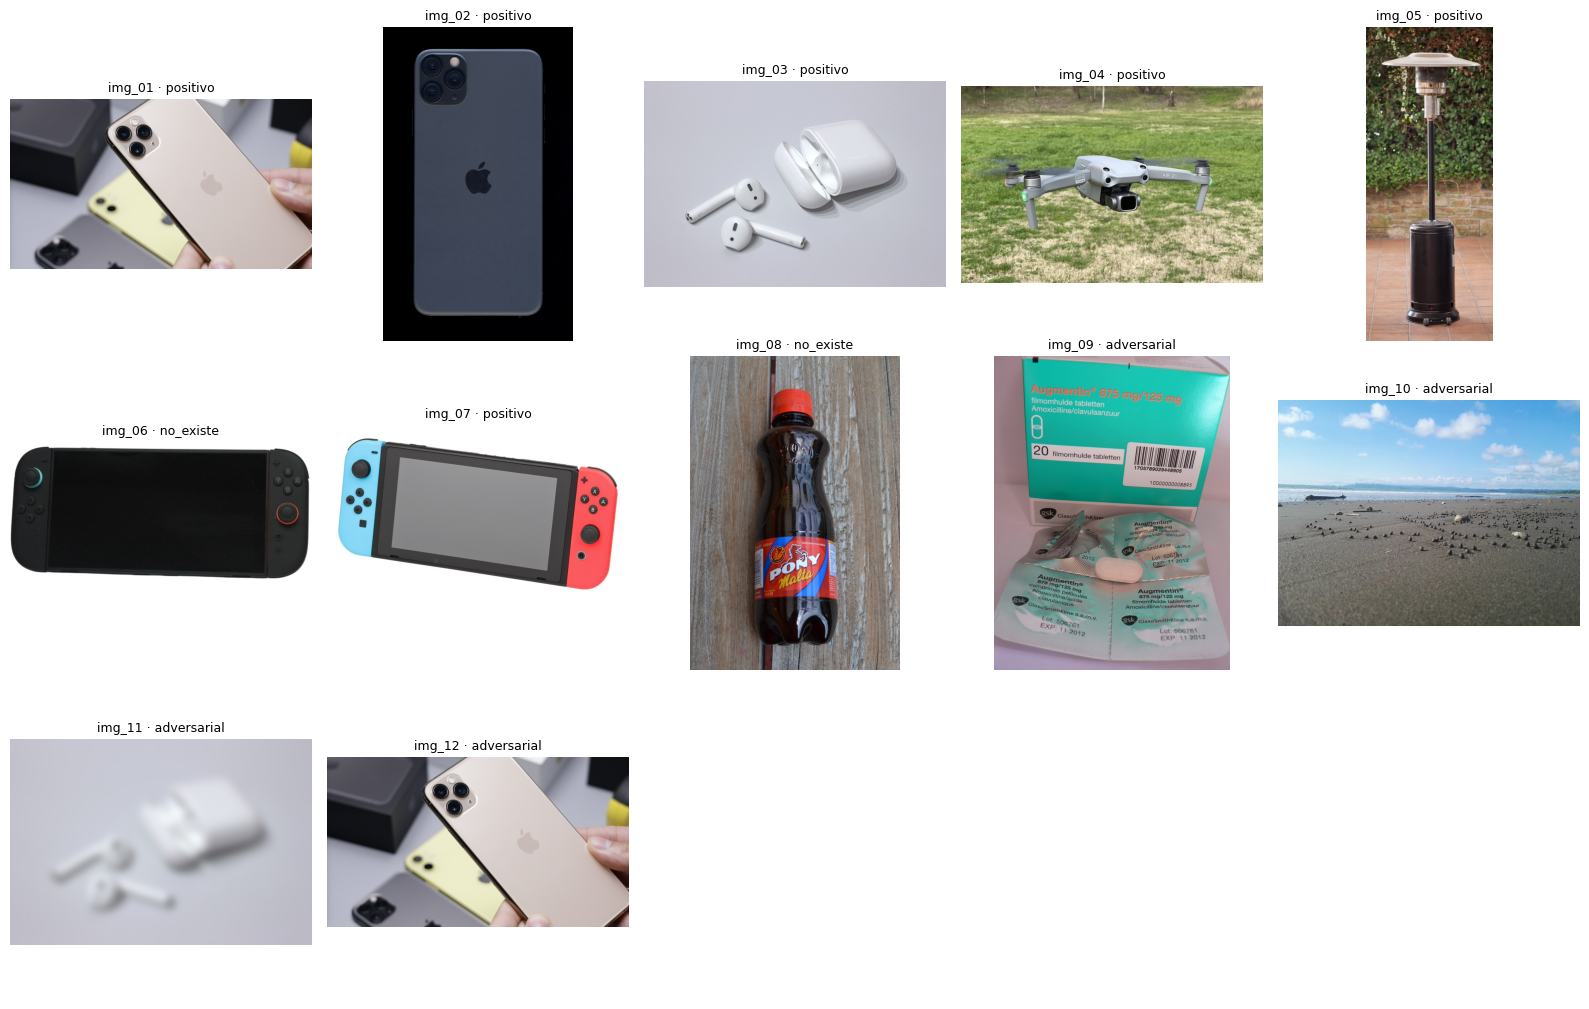

In [ ]:
EVAL_M4_DF = pd.read_csv(DIR_EVAL / "eval_set_m4.csv", dtype=str, encoding="utf-8-sig").fillna("")
_cand = pd.read_csv(DIR_VAL / "candidatas_imagenes_m4.csv", dtype=str, encoding="utf-8-sig").fillna("")
APROBADAS = set(_cand.loc[_cand["aprobada"].str.strip().str.lower().isin(["sí", "si"]), "id"])
FUENTES = pd.read_csv(DIR_EVAL / "fuentes_imagenes.csv", dtype=str, encoding="utf-8-sig").fillna("")

EVAL_IMG, FUERA = [], []
for r in EVAL_M4_DF.to_dict("records"):
    dueno = Path(r["imagen"]).stem                     
    ruta = DIR_IMAGENES / r["imagen"]
    if r["id"] not in APROBADAS or dueno not in APROBADAS:
        FUERA.append((r["id"], "foto sin aprobar en candidatas_imagenes_m4.csv"))
    elif not ruta.exists():
        FUERA.append((r["id"], f"falta {ruta.name}: correr eval_set/descargar_imagenes.py"))
    else:
        EVAL_IMG.append({**r, "ruta_imagen": ruta})
IMGS = {r["id"]: cargar_imagen(r["ruta_imagen"]) for r in EVAL_IMG}

print(f"{len(EVAL_IMG)} casos con imagen entran al eval set:")
print(pd.DataFrame(EVAL_IMG)[["id", "tipo", "criterio", "pregunta", "imagen"]].to_string(index=False))
for cid, motivo in FUERA:
    print(f"  fuera: {cid} ({motivo})")
assert len(EVAL_IMG) >= 5 and any(r["tipo"] == "adversarial" for r in EVAL_IMG), "S13 pide al menos 5 casos y uno adversarial."

_n = len(EVAL_IMG); _cols = 5
fig, axs = plt.subplots((_n + _cols - 1) // _cols, _cols, figsize=(3.2 * _cols, 3.4 * ((_n + _cols - 1) // _cols)))
for ax in np.atleast_1d(axs).ravel():
    ax.axis("off")
for ax, r in zip(np.atleast_1d(axs).ravel(), EVAL_IMG):
    ax.imshow(IMGS[r["id"]]); ax.set_title(f"{r['id']} · {r['tipo']}", fontsize=9)
plt.tight_layout(); plt.show()

### 3.3 Etiquetado del catálogo: ¿qué fichas son el producto de la foto?

Para cada caso que se califica contra el catálogo se arma una lista de candidatas: los relevantes del caso espejo de M3 (si hay), los títulos que coinciden con una búsqueda por palabras clave y lo que devuelven la búsqueda híbrida y el reranker con la pregunta escrita. El equipo marca en `es_el_producto` un **1** si la ficha es exactamente lo que dice `que_cuenta`, y un **0** si no.

Si el archivo ya existe no se sobrescribe: solo se agregan los casos que falten. Un caso con alguna fila vacía queda *pendiente*.

In [22]:
RUTA_ETIQUETADO = DIR_VAL / "etiquetado_catalogo_m4.xlsx"
M3_POR_ID = {p["id"]: p for p in EVAL_M3}
N_PALABRAS_CLAVE, N_HIBRIDA = 40, 15
CASOS_A_ETIQUETAR = [r for r in EVAL_IMG if r["criterio"] in ("acierto_respuesta", "segun_catalogo") or r["tipo"] == "no_existe"]

def candidatos_catalogo(r):
    filas = {}
    semilla = M3_POR_ID.get(r["semilla_m3"])
    if semilla:
        for pid in (semilla.get("relevantes_equipo") or semilla.get("relevantes_esci") or []):
            if pid in POS:
                filas[POS[pid]] = f"relevante en M3 ({r['semilla_m3']})"
    consulta = limpiar_texto(r["pregunta_techo"]) if r["pregunta_techo"] else ""
    if r["busqueda_catalogo"]:
        patron = re.compile(r["busqueda_catalogo"], re.I)
        hits = [i for i, t in enumerate(CATALOGO["titulo"]) if patron.search(t)]
        if len(hits) > N_PALABRAS_CLAVE and consulta:
            hits = [i for i, _ in reordenar(RERANKER_SISTEMA, consulta, hits)]
        for i in hits[:N_PALABRAS_CLAVE]:
            filas.setdefault(i, "título coincide con la búsqueda")
        print(f"  {r['id']}: {len(hits)} títulos coinciden con /{r['busqueda_catalogo']}/")
    if consulta:
        for i, _ in reordenar(RERANKER_SISTEMA, consulta, buscar_hibrida(consulta))[:N_HIBRIDA]:
            filas.setdefault(i, "híbrida + reranker con la pregunta escrita")
    return filas

def plantilla_etiquetado(casos):
    filas = []
    for r in casos:
        for i, origen in candidatos_catalogo(r).items():
            f = df_fichas.iloc[i]
            filas.append({"caso": r["id"], "que_cuenta": r["que_cuenta"], "product_id": CATALOGO["ids"][i],
                          "titulo": CATALOGO["titulo"][i], "marca": f.get("product_brand", ""),
                          "color": f.get("product_color", ""), "origen": origen, "es_el_producto": ""})
    return pd.DataFrame(filas)

if RUTA_ETIQUETADO.exists():
    _et = pd.read_excel(RUTA_ETIQUETADO, dtype=str).fillna("")
    _faltan = [r for r in CASOS_A_ETIQUETAR if r["id"] not in set(_et["caso"])]
    if _faltan:
        _et = pd.concat([_et, plantilla_etiquetado(_faltan)], ignore_index=True)
        _et.to_excel(RUTA_ETIQUETADO, index=False)
        print(f"Se agregaron {len(_faltan)} casos nuevos a {RUTA_ETIQUETADO.name}")
else:
    plantilla_etiquetado(CASOS_A_ETIQUETAR).to_excel(RUTA_ETIQUETADO, index=False)
    print(f"Plantilla creada: {RUTA_ETIQUETADO}. Llenen es_el_producto con 1 o 0 y vuelvan a correr desde §7.")

def leer_etiquetas():
    """{caso: [product_id que son el producto]} | None si el caso tiene filas sin etiquetar."""
    if not RUTA_ETIQUETADO.exists():
        return {}
    et = pd.read_excel(RUTA_ETIQUETADO, dtype=str).fillna("")
    rel = {}
    for caso, g in et.groupby("caso"):
        v = g["es_el_producto"].str.strip()
        rel[caso] = None if (v == "").any() else g.loc[v == "1", "product_id"].tolist()
    return rel

RELEVANTES_IMG = leer_etiquetas()
for r in CASOS_A_ETIQUETAR:
    v = RELEVANTES_IMG.get(r["id"])
    print(f"  {r['id']}: " + ("PENDIENTE de etiquetar" if v is None else f"{len(v)} fichas son el producto"))

  img_01: 3 fichas son el producto
  img_02: 2 fichas son el producto
  img_03: 3 fichas son el producto
  img_04: 2 fichas son el producto
  img_05: 7 fichas son el producto
  img_06: 0 fichas son el producto
  img_07: 6 fichas son el producto
  img_08: 0 fichas son el producto
  img_12: 0 fichas son el producto


## 4. `ver()` y el enchufe: `sistema_multimodal(pregunta, foto)`



In [23]:
VLM_ID = "Qwen/Qwen2-VL-2B-Instruct"
MIN_PIXELS, MAX_PIXELS = 256 * 28 * 28, 1024 * 28 * 28    # tope de resolución: las fotos de 1280 px no disparan la VRAM

VALVULA = ("Responde SOLO con lo que se ve en la imagen. Si un dato no se aprecia en la imagen, escribe null en ese campo. "
           "Si en la imagen no hay un producto que se pueda identificar, responde exactamente: {\"es_producto\": false}")
INSTRUCCION_DOMINIO = ("Un comprador te muestra esta foto para saber si una tienda en línea tiene ese producto. "
                       "Devuelve SOLO un JSON, en español, con estos campos: "
                       "{\"es_producto\": true o false, \"tipo_producto\": \"qué es, en pocas palabras\", "
                       "\"marca\": \"marca o null\", \"modelo\": \"modelo o null\", \"color\": \"color o null\", "
                       "\"texto_visible\": \"texto legible en el producto o null\"}")
MENSAJE_VALVULA = "No se aprecia en la imagen un producto que pueda buscar."
VACIOS = {"", "null", "none", "no se aprecia", "no se aprecia en la imagen", "desconocido", "n/a", "ninguno"}

@torch.no_grad()
def preguntar(imagen, pregunta, system=None, max_new_tokens=200):
    """La función de S13 (patrón INPUT): imagen + texto al VLM, salida greedy."""
    msgs = ([{"role": "system", "content": system}] if system else []) + \
           [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": pregunta}]}]
    texto = vproc.apply_chat_template(msgs, add_generation_prompt=True)
    ent = vproc(text=[texto], images=[imagen], return_tensors="pt").to(vlm.device)
    out = vlm.generate(**ent, max_new_tokens=max_new_tokens, do_sample=False)
    return vproc.batch_decode(out[:, ent["input_ids"].shape[1]:], skip_special_tokens=True)[0].strip()

def parsear_json(t):
    """El parser de S10/S11: si no hay JSON válido devuelve None y el caso cuenta como fallo."""
    i, j = t.find("{"), t.rfind("}")
    if i == -1 or j == -1:
        return None
    try:
        return json.loads(t[i:j + 1])
    except Exception:
        return None

def _valor(js, campo):
    """Valor de un campo del JSON, o None si el VLM lo dejó vacío o dijo que no se aprecia."""
    v = js.get(campo) if isinstance(js, dict) else None
    if v is None or isinstance(v, bool):
        return v
    v = str(v).strip()
    return None if _normal(v) in VACIOS else v

def ver(imagen, instruccion=None):
    """foto -> {crudo, json, valido, segundos}. Lo que sale de aquí entra a M3 como texto."""
    t = time.perf_counter()
    crudo = preguntar(imagen, instruccion or INSTRUCCION_DOMINIO, system=VALVULA)
    seg = time.perf_counter() - t
    js = parsear_json(crudo)
    return {"crudo": crudo, "json": js, "valido": isinstance(js, dict) and "es_producto" in js, "segundos": seg}

def producto_identificado(v):
    if not v["valido"]:
        return False
    es = v["json"].get("es_producto")
    if isinstance(es, str):
        es = _normal(es) in ("true", "si", "yes")
    return bool(es) and _valor(v["json"], "tipo_producto") is not None

def consulta_desde_json(js):
    """tipo + marca + modelo + color, normalizado como M1 y sin palabras repetidas."""
    partes = [_valor(js, c) for c in ("tipo_producto", "marca", "modelo", "color")]
    vistas, palabras = set(), []
    for w in limpiar_texto(" ".join(str(p) for p in partes if p and not isinstance(p, bool))).split():
        if w not in vistas:
            vistas.add(w); palabras.append(w)
    return " ".join(palabras)

assert parsear_json('texto {"es_producto": false} fin') == {"es_producto": False}
assert parsear_json("sin json") is None
assert consulta_desde_json({"tipo_producto": "Teléfono móvil", "marca": "Apple", "modelo": "iPhone 11 Pro Max",
                            "color": "null"}) == "teléfono móvil apple iphone 11 pro max"

In [24]:
from collections import Counter

class ErrorFormato(ValueError):
    """Una salida de un modelo o de una herramienta no cumple el contrato declarado."""

MENSAJE_ERROR_M4 = "No pude completar la consulta por un error del sistema. No se verificó si el producto está en el catálogo."
NOTA_CATALOGO = "Las fichas son del catálogo histórico de Amazon España (ESCI), no del inventario actual de la tienda."
NOMBRES_HERRAMIENTAS = ("verificar_existencia", "buscar_similares")

def lo_que_se_ve(js):
    """Los atributos que leyó ver(), tal como los escribió el VLM, para no mezclarlos con los de la ficha."""
    partes = [_valor(js, c) for c in ("tipo_producto", "marca", "modelo", "color")]
    return ", ".join(str(x) for x in partes if x and not isinstance(x, bool))

def nota_foto_ficha(js):
    return f"\n\nEn la foto se ve: {lo_que_se_ve(js)}. {NOTA_CATALOGO}"

def decision_enrutador(herramienta, crudo):
    """Revisión de M3 (M3-01): solo NINGUNA, sin texto adicional, es la decisión de no buscar.
    Una salida sin herramienta válida y sin NINGUNA es un error de formato, no una abstención."""
    if herramienta in NOMBRES_HERRAMIENTAS:
        return herramienta
    if isinstance(crudo, str) and crudo.strip().upper() == "NINGUNA":
        return "ninguna"
    raise ErrorFormato("el enrutador no devolvió una herramienta válida ni NINGUNA")

def validar_consulta(consulta):
    """En M4 la consulta no sale del enrutador sino de la foto: se valida la que arma M4."""
    if not isinstance(consulta, str) or not consulta.strip():
        raise ErrorFormato("la consulta armada desde la foto quedó vacía")
    return consulta.strip()

def validar_observacion(obs):
    """Estructura mínima de lo que devuelve la herramienta (no su relevancia)."""
    if not isinstance(obs, dict) or not isinstance(obs.get("ranking"), list) or not isinstance(obs.get("resultado"), list):
        raise ErrorFormato("la herramienta no devolvió ranking y resultado como listas")
    if not set(obs["resultado"]) <= set(obs["ranking"]):
        raise ErrorFormato("el resultado de la herramienta no está dentro de su ranking")

def _cerrar(nombre, p, estado, consulta, ranking, ctx, respuesta, lat, t_total, extra):
    lat["total"] = time.perf_counter() - t_total
    s = _salida(nombre, p, consulta, ranking, ctx, respuesta, lat, extra)
    s.update({"estado": estado, "evaluacion_valida": True})
    return s

def _salida_error(nombre, p, etapa, exc, lat, t_total, extra):
    """Un error no es 'no existe' ni una abstención correcta: se registra, se cuenta y queda fuera de la nota."""
    lat["total"] = time.perf_counter() - t_total
    s = {"sistema": nombre, "id": p["id"], "consulta_busqueda": extra.get("consulta_desde_foto"),
         "ranking": [], "contexto_ids": [], "contexto": [], "pantalla": [], "citados": [],
         "respuesta": MENSAJE_ERROR_M4, "respuesta_generada": None, "apertura": "error", "abstiene": False,
         "latencia": {k: round(v, 3) for k, v in lat.items()}}
    s.update(extra)
    s.update({"estado": "error_formato" if isinstance(exc, ErrorFormato) else "error_operativo",
              "evaluacion_valida": False, "error_etapa": etapa, "error_tipo": type(exc).__name__})
    print(f"  [{nombre} {p['id']}] {s['estado']} en la etapa '{etapa}' ({type(exc).__name__})")
    return s

def correr_foto(nombre, p, imagen, ver_fn, consulta_fn):
    """El enchufe de M4, común a M4 y M4.1: foto -> ver() -> consulta -> enrutador -> verificar_existencia -> generador.
    Cada salida lleva su estado; los errores quedan separados de las decisiones del dominio."""
    lat, t_total, etapa = {}, time.perf_counter(), "ver"
    extra = {"consulta_original": p["pregunta"], "herramienta": None, "consulta_desde_foto": None}
    try:
        v = ver_fn(imagen); lat["ver"] = v["segundos"]
        extra.update({"ver_crudo": v["crudo"], "ver_json": v["json"], "ver_valido": v["valido"]})
        extra.update({f"ver_{k}": v[k] for k in ("descripcion", "descripcion_es_json") if k in v})
        if not v["valido"]:
            raise ErrorFormato("ver() no devolvió un JSON válido")
        if not producto_identificado(v):                               # válvula: no hay producto que buscar
            return _cerrar(nombre, p, "sin_producto", None, [], [], f"{APERTURAS['abstiene']} {MENSAJE_VALVULA}",
                           lat, t_total, extra)
        etapa = "consulta"
        consulta = validar_consulta(consulta_fn(v["json"], p["pregunta"]))
        pregunta_aum = f"{p['pregunta']} (En la foto se ve: {consulta_desde_json(v['json'])})"
        etapa = "enrutamiento"
        t = time.perf_counter(); herramienta, _, crudo, json_ok = enrutar(pregunta_aum); lat["enrutamiento"] = time.perf_counter() - t
        extra.update({"herramienta": herramienta, "salida_enrutador": crudo, "enrutador_formato_ok": json_ok,
                      "consulta_desde_foto": consulta, "pregunta_aumentada": pregunta_aum})
        etapa = "esquema_enrutador"
        if decision_enrutador(herramienta, crudo) == "ninguna":       # p. ej. un medicamento con receta
            return _cerrar(nombre, p, "abstencion_dominio", consulta, [], [], APERTURAS["abstiene"], lat, t_total, extra)
        etapa = "herramienta"
        obs = verificar_existencia(consulta)                           # alcance M4: existencia, con la consulta de la foto
        etapa = "esquema_observacion"
        validar_observacion(obs)
        lat["recuperacion"], lat["reranking"] = obs["t_rec"], obs["t_rr"]
        if not obs["resultado"]:
            return _cerrar(nombre, p, "sin_resultados", consulta, obs["ranking"], [], APERTURAS["abstiene"], lat, t_total, extra)
        etapa = "generacion"
        encabezado = "Usaste la herramienta verificar_existencia con lo que se ve en la foto y obtuviste estas fichas del catálogo:"
        t = time.perf_counter(); respuesta = generar(SYSTEM_RAG, armar_prompt(obs["resultado"], pregunta_aum, encabezado)); lat["generacion"] = time.perf_counter() - t
        if not isinstance(respuesta, str) or not respuesta.strip():
            raise ErrorFormato("el generador no devolvió texto")
        etapa = "presentacion"
        s = _cerrar(nombre, p, "respuesta_generada", consulta, obs["ranking"], obs["resultado"], respuesta, lat, t_total, extra)
        s["respuesta"] += nota_foto_ficha(v["json"])                  # foto y ficha separadas, sin inferir stock
        return s
    except Exception as exc:                                           # no atrapa KeyboardInterrupt
        return _salida_error(nombre, p, etapa, exc, lat, t_total, extra)

def sistema_multimodal(p, imagen=None):
    """pregunta (+ foto) -> respuesta. Sin foto es el sistema D de M3, sin tocar."""
    if imagen is None:
        return sistema_D(p)
    return correr_foto("M4", p, imagen, ver, lambda js, pregunta: consulta_desde_json(js))

assert decision_enrutador("ninguna", " ninguna\n") == "ninguna"
assert decision_enrutador("verificar_existencia", '{"tool": "verificar_existencia"}') == "verificar_existencia"
for _malo in ("", "No digas NINGUNA", "{", None):
    try:
        decision_enrutador("ninguna", _malo)
        raise AssertionError(f"debió ser error de formato: {_malo!r}")
    except ErrorFormato:
        pass
assert lo_que_se_ve({"tipo_producto": "dron", "marca": "DJI", "modelo": "Air 2S", "color": "null"}) == "dron, DJI, Air 2S"


### 4.1 M4.1: la variante declarada después de la primera corrida



In [25]:
INSTRUCCION_DESCRIBIR = "Describe en dos frases, en español, el producto que se ve en la imagen. Si no hay un producto, dilo."
# Válvula de S11 (lámina 21) sin mencionar JSON. La primera versión usaba VALVULA, que habla de JSON, y el VLM
# respondía solo {"es_producto": ...} en vez de describir (10 de 12 fotos en la corrida del 20 oct).
VALVULA_DESCRIBIR = ("Responde SOLO con lo que se ve en la imagen, en texto corrido y sin JSON. "
                     "Si algo no se aprecia en la imagen, di: no se aprecia en la imagen.")
ATRIBUTOS_TEXTO = re.compile(r"\b\d+(?:[.,]\d+)?\s*(?:gb|tb|mb|ml|cl|l|w|kw|cm|mm|kg|g|mah|pulgadas|tazas)\b|\bsin\s+\w+", re.I)

def parece_json(texto):
    """Control del paso 1: si la 'descripción' trae JSON, el VLM no describió."""
    return "{" in texto or "es_producto" in texto

def ver_dos_pasos(imagen):
    """Describir antes de preguntar (S11 y S13): una descripción libre y luego el JSON, anclado en ella."""
    t = time.perf_counter()
    descripcion = preguntar(imagen, INSTRUCCION_DESCRIBIR, system=VALVULA_DESCRIBIR, max_new_tokens=120)
    crudo = preguntar(imagen, f"Tu descripción de la imagen: {descripcion}\n\n{INSTRUCCION_DOMINIO}", system=VALVULA)
    js = parsear_json(crudo)
    return {"crudo": crudo, "json": js, "valido": isinstance(js, dict) and "es_producto" in js,
            "segundos": time.perf_counter() - t, "descripcion": descripcion, "descripcion_es_json": parece_json(descripcion)}

def consulta_m41(js, pregunta):
    """Identidad (marca + modelo, o tipo + marca) más los atributos del texto que la foto no puede mostrar."""
    marca, modelo, tipo = _valor(js, "marca"), _valor(js, "modelo"), _valor(js, "tipo_producto")
    partes = [marca, modelo] if modelo else [tipo, marca]
    partes += ATRIBUTOS_TEXTO.findall(pregunta)
    vistas, palabras = set(), []
    for w in limpiar_texto(" ".join(str(x) for x in partes if x and not isinstance(x, bool))).split():
        if w not in vistas:
            vistas.add(w); palabras.append(w)
    return " ".join(palabras)

def sistema_multimodal_m41(p, imagen=None):
    """Igual que sistema_multimodal (mismo enchufe y mismo contrato), con ver() en dos pasos y la consulta de consulta_m41."""
    if imagen is None:
        return sistema_D(p)
    return correr_foto("M4.1", p, imagen, ver_dos_pasos, consulta_m41)

assert parece_json('{"es_producto": true}') and not parece_json("Un dron gris sobre un campo de césped.")
assert consulta_m41({"tipo_producto": "celular", "marca": "Apple", "modelo": "iPhone 11 Pro Max", "color": "oro"},
                    "¿Lo tienen de 512 GB?") == "apple iphone 11 pro max 512 gb"
assert consulta_m41({"tipo_producto": "estufa de exterior", "marca": None, "modelo": None, "color": "negro"},
                    "¿Venden estufas como esta?") == "estufa de exterior"

## 5. Fase A: todo lo que es solo texto

Con el verificador de M3 cargado (lo usa `buscar_similares`) se corren:

1. **Los 49 casos de M3** por `sistema_multimodal(pregunta)`, sin foto. Como el enchufe no toca a `sistema_D`, deberían salir iguales a M3; la celda compara respuesta por respuesta.
2. **Línea base honesta para los casos con foto:** M3 recibe la pregunta sola ("¿Tienen este celular?"), sin poder ver.
3. **Techo:** M3 recibe la pregunta que escribiría una persona que sabe qué es el producto ("¿Tienen el iPhone 11 Pro Max en color oro?"). La distancia entre M4 y el techo es lo que pierde el VLM.

In [26]:
_sin_foto = lambda p: sistema_multimodal(p, None)
_sin_foto.nombre = "M4 sin foto (49 de M3)"
SALIDAS_49 = correr(_sin_foto, EVAL_M3)

iguales = sum(s["respuesta_generada"] == SALIDAS_M3_D[s["id"]]["respuesta_generada"] for s in SALIDAS_49)
misma_pantalla = sum(s["pantalla"] == SALIDAS_M3_D[s["id"]]["pantalla"] for s in SALIDAS_49)
print(f"Iguales a M3: respuesta {iguales}/{len(SALIDAS_49)} | primera pantalla {misma_pantalla}/{len(SALIDAS_49)}")
for s in SALIDAS_49:
    if s["respuesta_generada"] != SALIDAS_M3_D[s["id"]]["respuesta_generada"]:
        print(f"  distinta: {s['id']}  M3 {SALIDAS_M3_D[s['id']]['respuesta_generada'][:70]!r}  M4 {s['respuesta_generada'][:70]!r}")

  M4 sin foto (49 de M3) 49 preguntas | abstenciones 7 | latencia media 2.20s
Iguales a M3: respuesta 49/49 | primera pantalla 49/49


In [27]:
def p_imagen(r, pregunta):
    return {"id": r["id"], "pregunta": pregunta}

SALIDAS_IMG = {"M3 pregunta sola": {}, "M3 techo": {}, "M4": {}}
_sola = lambda p: sistema_D(p); _sola.nombre = "M3 con la pregunta sola"
for s in correr(_sola, [p_imagen(r, r["pregunta"]) for r in EVAL_IMG]):
    SALIDAS_IMG["M3 pregunta sola"][s["id"]] = s
_techo = lambda p: sistema_D(p); _techo.nombre = "M3 techo (pregunta escrita)"
for s in correr(_techo, [p_imagen(r, r["pregunta_techo"]) for r in EVAL_IMG if r["pregunta_techo"]]):
    SALIDAS_IMG["M3 techo"][s["id"]] = s

for r in EVAL_IMG:
    a = SALIDAS_IMG["M3 pregunta sola"][r["id"]]; b = SALIDAS_IMG["M3 techo"].get(r["id"])
    print(f"{r['id']}  sola: {a['apertura']:<9} {a['respuesta'][:60]!r}")
    if b:
        print(f"{'':6}  techo: {b['apertura']:<9} {b['respuesta'][:60]!r}")

liberar("verificador")   # fin de la fase A: buscar_similares ya no se usa

  M3 con la pregunta sola 12 preguntas | abstenciones 3 | latencia media 2.33s
  M3 techo (pregunta escrita) 10 preguntas | abstenciones 4 | latencia media 1.77s
img_01  sola: afirma    'Sí, lo tenemos: [B07H2KDP55] alcatel 3026 - teléfono móvil d'
        techo: afirma    'Sí, lo tenemos: [B07XS4J7R6] apple iphone 11 pro max (256 gb'
img_02  sola: afirma    'Sí, lo tenemos: [B07H2KDP55] alcatel 3026 - teléfono móvil d'
        techo: afirma    'Sí, lo tenemos: apple iphone 11 pro max (256 gb) [B07XS47XDK'
img_03  sola: abstiene  'No tengo esa información en mis fuentes.'
        techo: afirma    'Sí, lo tenemos: [B07PZRD7C5] apple airpods con estuche de ca'
img_04  sola: afirma    'Sí, lo tenemos: [B096RY5RLN] drones con cámara 1080p hd fpv,'
        techo: afirma    'Sí, lo tenemos: dji air 2s fly more combo- drone, 3 [B08YQWC'
img_05  sola: afirma    'Sí, lo tenemos: [B01MQLZ13B] campingaz estufa de gas cr 5000'
        techo: afirma    'Sí, lo tenemos: [B00EF9MHAI] estufa exterior 

## 6. Fase B: el VLM

### 6.1 `ver()` sola, sobre tres fotos, con su latencia (S13, parte 1)

In [28]:
try:
    import torchvision   # el procesador de Qwen2-VL (transformers 4.57) lo exige
except ImportError as e:
    _base = torch.__version__.split("+")[0]
    _indice = ("cu" + torch.version.cuda.replace(".", "")) if torch.version.cuda else "cpu"
    raise ImportError(f'Falta torchvision. Instálenlo sin cambiar torch: %pip install "torch=={_base}" torchvision '
                      f'--index-url https://download.pytorch.org/whl/{_indice} ; luego reinicien el kernel.') from e

from transformers import Qwen2VLForConditionalGeneration, AutoProcessor

DTYPE_VLM = (torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16) if DEVICE == "cuda" else torch.float32
vlm = Qwen2VLForConditionalGeneration.from_pretrained(VLM_ID, dtype=DTYPE_VLM).to(DEVICE).eval()
vproc = AutoProcessor.from_pretrained(VLM_ID, min_pixels=MIN_PIXELS, max_pixels=MAX_PIXELS)
_ = preguntar(next(iter(IMGS.values())), "hola", max_new_tokens=2)   # calentamiento, fuera de toda medición
print("VLM listo:", VLM_ID, "|", DTYPE_VLM)
if DEVICE == "cuda":
    print(f"VRAM ocupada: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

Loading checkpoint shards: 100%|██████████| 2/2 [00:00<00:00, 14.60it/s]
The image processor of type `Qwen2VLImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. Note that this behavior will be extended to all models in a future release.


VLM listo: Qwen/Qwen2-VL-2B-Instruct | torch.bfloat16
VRAM ocupada: 7.88 GB


In [29]:
PRUEBA_VER = [c for c in ("img_03", "img_07", "img_10") if c in IMGS] or list(IMGS)[:3]
for cid in PRUEBA_VER:
    v = ver(IMGS[cid])
    print(f"[{cid}] {v['segundos']:.2f}s | JSON válido: {v['valido']} | producto: {producto_identificado(v)}")
    print(f"   {v['json'] if v['valido'] else v['crudo'][:200]}")
    if producto_identificado(v):
        print(f"   consulta: {consulta_desde_json(v['json'])!r}")

[img_03] 1.73s | JSON válido: True | producto: True
   {'es_producto': True, 'tipo_producto': 'auriculares inalámbricos', 'marca': 'Apple', 'modelo': 'AirPods', 'color': 'blanco'}
   consulta: 'auriculares inalámbricos apple airpods blanco'
[img_07] 1.91s | JSON válido: True | producto: True
   {'es_producto': True, 'tipo_producto': 'videojuego', 'marca': 'Nintendo', 'modelo': 'Switch', 'color': 'rojo y azul', 'texto_visible': 'Nintendo Switch'}
   consulta: 'videojuego nintendo switch rojo y azul'
[img_10] 1.58s | JSON válido: True | producto: True
   {'es_producto': True, 'tipo_producto': 'rocas', 'marca': None, 'modelo': None, 'color': None, 'texto_visible': None}
   consulta: 'rocas'


### 6.2 Los casos con foto, de punta a punta

In [30]:
for r in EVAL_IMG:
    s = sistema_multimodal(p_imagen(r, r["pregunta"]), IMGS[r["id"]])
    SALIDAS_IMG["M4"][r["id"]] = s
    print(f"{r['id']}  {s['latencia']['total']:.2f}s (ver {s['latencia'].get('ver', float('nan')):.2f}s) | {s['estado']:<18} | "
          f"{s['apertura']:<9} | consulta {s.get('consulta_desde_foto')!r} | {s['respuesta'][:70]!r}")
print("\nEstados:", dict(Counter(s["estado"] for s in SALIDAS_IMG["M4"].values())))


img_01  6.30s (ver 2.02s) | respuesta_generada | afirma    | consulta 'celular apple iphone 11 pro max oro' | 'Sí, lo tenemos: [B07XS4J7R6] apple iphone 11 pro max (256 gb) - oro | '
img_02  4.09s (ver 1.92s) | respuesta_generada | similares | consulta 'celular apple iphone 11 pro max negro' | 'No lo tenemos exacto, pero hay productos parecidos: [B07XS47XG8] apple'
img_03  4.32s (ver 1.61s) | respuesta_generada | afirma    | consulta 'auriculares inalámbricos apple airpods blanco' | 'Sí, lo tenemos: [B01M1EEPOB] apple earpods con conector lightning | ma'
img_04  2.28s (ver 1.51s) | sin_resultados     | abstiene  | consulta 'drone dji air 2s gris' | 'No tengo esa información en mis fuentes.'
img_05  3.77s (ver 1.69s) | respuesta_generada | afirma    | consulta 'calentador de exterior' | 'Sí, lo tenemos: [B0181OJ1Z6] outsunny calefactor de infrarrojos estufa'
img_06  3.43s (ver 1.69s) | respuesta_generada | similares | consulta 'controlador de videojuegos nintendo switch negro' | 'No lo 

### 6.3 M4.1, los mismos casos (variante de §4.1)

In [31]:
SALIDAS_IMG["M4.1"] = {}
for r in EVAL_IMG:
    s = sistema_multimodal_m41(p_imagen(r, r["pregunta"]), IMGS[r["id"]])
    SALIDAS_IMG["M4.1"][r["id"]] = s
    print(f"{r['id']}  {s['latencia']['total']:.2f}s (ver {s['latencia'].get('ver', float('nan')):.2f}s) | {s['estado']:<18} | "
          f"{s['apertura']:<9} | consulta {s.get('consulta_desde_foto')!r} | {s['respuesta'][:70]!r}")
    print(f"        descripción: {(s.get('ver_descripcion') or '')[:110]!r}")

n_json = sum(bool(s.get("ver_descripcion_es_json")) for s in SALIDAS_IMG["M4.1"].values())
print(f"\nDescripciones que salieron como JSON (el paso 1 no describió): {n_json}/{len(SALIDAS_IMG['M4.1'])}")
print("Estados:", dict(Counter(s["estado"] for s in SALIDAS_IMG["M4.1"].values())))


img_01  7.69s (ver 3.42s) | respuesta_generada | afirma    | consulta 'apple iphone 11 pro max' | 'Sí, lo tenemos: [B07XS5FQ3N] apple iphone 11 pro max (256 gb) - de en '
        descripción: 'Un teléfono móvil de Apple con un diseño de color dorado, con tres cámaras traseras y el logotipo de Apple en '
img_02  5.49s (ver 3.20s) | respuesta_generada | afirma    | consulta 'apple iphone 11 pro max' | 'Sí, lo tenemos: apple iphone 11 pro max (256 gb) [B07XS5FQ3N], [B07XS5'
        descripción: 'El producto que se ve en la imagen es un iPhone de Apple, específicamente el modelo iPhone 11 Pro Max.'
img_03  4.78s (ver 2.99s) | respuesta_generada | afirma    | consulta 'apple airpods' | 'Sí, lo tenemos: [B07PZRD7C5] apple airpods con estuche de carga inalám'
        descripción: 'En la imagen se pueden ver auriculares inalámbricos blancos y una caja de almacenamiento.'
img_04  4.25s (ver 2.71s) | respuesta_generada | afirma    | consulta 'dji air 2s' | 'Sí, lo tenemos: dji air 2s fly more co

## 7. El harness: la vara de M3, con criterios que saben mirar




In [32]:
def completar_etiquetado():
    """Toda ficha que un sistema mostró en su primera pantalla tiene que estar etiquetada. Si falta, se agrega vacía."""
    if not RUTA_ETIQUETADO.exists():
        return 0
    et = pd.read_excel(RUTA_ETIQUETADO, dtype=str).fillna("")
    ya, casos, nuevas = set(zip(et["caso"], et["product_id"])), {r["id"]: r for r in CASOS_A_ETIQUETAR}, []
    for sistema, salidas in SALIDAS_IMG.items():
        for cid, s in salidas.items():
            for pid in (s["pantalla"][:K_CONTEXTO] if cid in casos else []):
                if (cid, pid) not in ya and pid in POS:
                    f = df_fichas.iloc[POS[pid]]
                    nuevas.append({"caso": cid, "que_cuenta": casos[cid]["que_cuenta"], "product_id": pid,
                                   "titulo": CATALOGO["titulo"][POS[pid]], "marca": f.get("product_brand", ""),
                                   "color": f.get("product_color", ""), "origen": f"mostrada por {sistema}", "es_el_producto": ""})
                    ya.add((cid, pid))
    if nuevas:
        pd.concat([et, pd.DataFrame(nuevas)], ignore_index=True).to_excel(RUTA_ETIQUETADO, index=False)
        print(f"Se agregaron {len(nuevas)} fichas mostradas que no estaban en {RUTA_ETIQUETADO.name}: etiquétenlas y vuelvan a correr desde §7.")
    return len(nuevas)

completar_etiquetado()
RELEVANTES_IMG = leer_etiquetas()

def criterio_efectivo(r):
    if r["criterio"] != "segun_catalogo":
        return r["criterio"]
    rel = RELEVANTES_IMG.get(r["id"])
    return None if rel is None else ("acierto_respuesta" if rel else "no_afirma")

def citas_en_orden(s):
    """Ids del contexto citados en la respuesta, en el orden en que aparecen en el texto."""
    texto = (s.get("respuesta") or "").upper()
    pos = sorted((texto.find(pid.upper()), pid) for pid in s.get("contexto_ids", []) if pid.upper() in texto)
    return [pid for _, pid in pos]

def nota_caso(r, s, regla="d3"):
    """d3: la D3 de M3 sin cambios (oficial). csv: lo escrito en la columna esperado (1 de las 3 primeras).
    cita: la primera ficha citada en el texto es el producto. Las tres solo difieren en acierto_respuesta."""
    c = criterio_efectivo(r)
    if c is None or s is None or s.get("evaluacion_valida") is False:
        return None
    if c == "valvula":
        return float(bool(s["abstiene"]))
    if c == "no_afirma":
        return float(s["apertura"] != "afirma")
    rel = RELEVANTES_IMG.get(r["id"])
    if not rel:                                    # pendiente, o el etiquetado no encontró el producto
        return None
    if regla == "d3":
        p = {"tipo": "gold", "intencion": "existencia", "relevantes_esci": rel, "relevantes_equipo": rel}
        return float(dimension_3(p, s)["acierto_respuesta"])
    afirma = s["apertura"] == APERTURA_CORRECTA["existencia"]
    if regla == "csv":
        return float(afirma and any(pid in set(rel) for pid in s["pantalla"][:3]))
    citas = citas_en_orden(s)
    return float(afirma and bool(citas) and citas[0] in set(rel))

def afirmacion_falsa(r, s):
    if s is not None and s.get("evaluacion_valida") is False:
        return None
    if s is None or s["apertura"] != "afirma":
        return False if s is not None else None
    rel = RELEVANTES_IMG.get(r["id"])
    if rel is None and r["tipo"] != "adversarial":
        return None
    return not any(pid in set(rel or []) for pid in s["pantalla"][:3])

def ndcg_caso(r, s):
    rel = RELEVANTES_IMG.get(r["id"])
    if not rel or s is None or s.get("evaluacion_valida") is False:
        return None
    return ndcg_con_ideal([int(pid in set(rel)) for pid in s["ranking"][:10]], len(rel))

PATRON_CITA = re.compile(r"\[([A-Za-z0-9]{10})\]")
ABSTENCIONES_CONTRATO = {APERTURAS["abstiene"], f"{APERTURAS['abstiene']} {MENSAJE_VALVULA}"}

def auditar_citas(s):
    """Auditoría sintáctica de la revisión de M3 (M3-02), al lado de D3 y sin cambiarla. No certifica que la respuesta
    sea correcta ni el stock: solo que el texto cite lo recuperado y que la abstención sea la del contrato."""
    if s is None or s.get("evaluacion_valida") is False:
        return {"citas_emitidas": None, "citas_del_contexto": None, "citas_desconocidas": None,
                "falta_marcador": None, "abstencion_fuera_de_contrato": None}
    texto = s.get("respuesta") or ""
    ctx = {pid.upper() for pid in s.get("contexto_ids", [])}
    emitidas = [c.upper() for c in PATRON_CITA.findall(texto)]
    del_ctx = [c for c in emitidas if c in ctx]
    return {"citas_emitidas": len(emitidas), "citas_del_contexto": len(del_ctx),
            "citas_desconocidas": len(emitidas) - len(del_ctx),
            "falta_marcador": bool(not s["abstiene"] and ctx and not emitidas),
            "abstencion_fuera_de_contrato": bool(s["abstiene"] and texto.strip() not in ABSTENCIONES_CONTRATO)}

assert auditar_citas({"respuesta": "Sí, lo tenemos: x [B000000001] y [B00000000Z]", "contexto_ids": ["B000000001"],
                      "abstiene": False})["citas_desconocidas"] == 1
assert auditar_citas({"respuesta": APERTURAS["abstiene"] + " Pero sí hay uno.", "contexto_ids": [],
                      "abstiene": True})["abstencion_fuera_de_contrato"]

def _coincide(texto, alias):
    t = _normal(texto)
    return any(_normal(a) and _normal(a) in t for a in alias.split("|"))

def nota_campos(r, s):
    if s is None or "ver_json" not in s:
        return None
    js = s["ver_json"]
    v = {"json": js, "valido": isinstance(js, dict) and "es_producto" in js}
    if r["gold_es_producto"] == "no":
        return float(not producto_identificado(v))
    if not v["valido"]:
        return 0.0
    texto = consulta_desde_json(js) + " " + str(_valor(js, "texto_visible") or "")
    golds = [r[f"gold_{c}"] for c in ("tipo", "marca", "modelo", "color") if r[f"gold_{c}"]]
    return sum(_coincide(texto, g) for g in golds) / len(golds) if golds else None

filas = []
for r in EVAL_IMG:
    for sistema, salidas in SALIDAS_IMG.items():
        s = salidas.get(r["id"])
        if s is None:
            continue
        filas.append({"sistema": sistema, "id": r["id"], "tipo": r["tipo"], "criterio": r["criterio"],
                      "criterio_efectivo": criterio_efectivo(r), "nota": nota_caso(r, s),
                      "nota_csv": nota_caso(r, s, "csv"), "nota_cita": nota_caso(r, s, "cita"),
                      "estado": s.get("estado", "sistema_D"), "evaluacion_valida": s.get("evaluacion_valida", True),
                      **auditar_citas(s),
                      "afirmacion_falsa": afirmacion_falsa(r, s), "ndcg10": ndcg_caso(r, s),
                      "campos": nota_campos(r, s) if sistema.startswith("M4") else None,
                      "apertura": s["apertura"], "abstiene": s["abstiene"],
                      "consulta": s.get("consulta_desde_foto") or s.get("consulta_busqueda"),
                      "herramienta_enrutador": s.get("herramienta"),
                      "seg_total": s["latencia"]["total"], "seg_ver": s["latencia"].get("ver"),
                      "respuesta": s["respuesta"]})
DET_IMG = pd.DataFrame(filas)
pendientes = sorted(r["id"] for r in EVAL_IMG
                    if r["criterio"] in ("acierto_respuesta", "segun_catalogo") and RELEVANTES_IMG.get(r["id"]) is None)
print("Pendientes de etiquetado:", pendientes or "ninguno")
for sistema, g in DET_IMG.groupby("sistema", sort=False):
    print(f"  {sistema:<17} válidas {int(g['evaluacion_valida'].sum())}/{len(g)} | estados {dict(Counter(g['estado']))}")
for r in EVAL_IMG:
    rel = RELEVANTES_IMG.get(r["id"])
    if r["tipo"] == "no_existe" and rel:
        print(f"AVISO {r['id']}: el etiquetado encontró el producto en el catálogo ({len(rel)} fichas). "
              "El criterio declarado (no_afirma) ya no aplica: revisar el caso antes de reportar.")
    if r["criterio"] == "acierto_respuesta" and rel == []:
        print(f"AVISO {r['id']}: el etiquetado no encontró el producto en el catálogo. El criterio declarado no aplica.")
for regla, col in (("D3 (oficial)", "nota"), ("regla del CSV", "nota_csv"), ("primera cita", "nota_cita")):
    print(f"Aciertos con {regla:<13}: " + " | ".join(
        f"{sis} {int(g[col].dropna().sum())}/{g[col].notna().sum()}" for sis, g in DET_IMG.groupby("sistema", sort=False)))
DET_IMG.pivot_table(index=["id", "tipo", "criterio"], columns="sistema", values="nota", aggfunc="first")

Pendientes de etiquetado: ninguno
  M3 pregunta sola  válidas 12/12 | estados {'sistema_D': 12}
  M3 techo          válidas 10/10 | estados {'sistema_D': 10}
  M4                válidas 12/12 | estados {'respuesta_generada': 9, 'sin_resultados': 3}
  M4.1              válidas 12/12 | estados {'respuesta_generada': 7, 'sin_resultados': 3, 'abstencion_dominio': 1, 'sin_producto': 1}
Aciertos con D3 (oficial) : M3 pregunta sola 3/12 | M3 techo 8/10 | M4 4/12 | M4.1 7/12
Aciertos con regla del CSV: M3 pregunta sola 3/12 | M3 techo 10/10 | M4 5/12 | M4.1 9/12
Aciertos con primera cita : M3 pregunta sola 3/12 | M3 techo 10/10 | M4 5/12 | M4.1 8/12


,,sistema,M3 pregunta sola,M3 techo,M4,M4.1
id,tipo,criterio,,,,
img_01,positivo,acierto_respuesta,0.0,0.0,0.0,0.0
img_02,positivo,segun_catalogo,0.0,1.0,0.0,0.0
img_03,positivo,acierto_respuesta,0.0,1.0,0.0,1.0
img_04,positivo,acierto_respuesta,0.0,1.0,0.0,1.0
img_05,positivo,acierto_respuesta,0.0,0.0,0.0,0.0
img_06,no_existe,no_afirma,0.0,1.0,1.0,0.0
img_07,positivo,acierto_respuesta,1.0,1.0,1.0,0.0
img_08,no_existe,no_afirma,0.0,1.0,1.0,1.0
img_09,adversarial,valvula,1.0,1.0,1.0,1.0


In [33]:
def detalle_49(salidas):
    filas = []
    for p, s in zip(EVAL_M3, salidas):
        filas.append({"id": p["id"], "tipo": p["tipo"], "intencion": p["intencion"], **dimension_1(p, s), **dimension_3(p, s), **auditar_citas(s),
                      "apertura": s["apertura"], "latencia_total": s["latencia"]["total"]})
    return pd.DataFrame(filas).set_index("id")

DET_49_M4 = detalle_49(SALIDAS_49)
DET_49_M3 = DETALLE_M3_D.loc[DET_49_M4.index]
print(f"Aciertos de respuesta en los 49: M3 {int(DET_49_M3['acierto_respuesta'].sum())} | M4 {int(DET_49_M4['acierto_respuesta'].sum())}")

Aciertos de respuesta en los 49: M3 17 | M4 17


## 8. La tabla de delta contra M3



In [34]:
def media(serie):
    v = pd.to_numeric(pd.Series(serie), errors="coerce").dropna()
    return None if v.empty else float(v.mean())

def fmt(x, dec=2):
    return "n/a" if x is None else f"{x:.{dec}f}"

def fmt_n(serie, total):
    """Media y cuántos casos tienen nota: los pendientes de etiquetado no entran al promedio, y se dice."""
    v = pd.to_numeric(pd.Series(serie), errors="coerce").dropna()
    return "n/a" if v.empty else f"{v.mean():.2f} ({len(v)}/{total} con nota)"

m4 = DET_IMG[DET_IMG["sistema"] == "M4"].set_index("id")
m41 = DET_IMG[DET_IMG["sistema"] == "M4.1"].set_index("id")
sola = DET_IMG[DET_IMG["sistema"] == "M3 pregunta sola"].set_index("id")
techo = DET_IMG[DET_IMG["sistema"] == "M3 techo"].set_index("id")
responder = [r["id"] for r in EVAL_IMG if r["tipo"] in ("positivo", "no_existe")]
adversos = [r["id"] for r in EVAL_IMG if r["tipo"] == "adversarial"]

a49_m3 = DET_49_M3["acierto_respuesta"].astype(float).tolist()
a49_m4 = DET_49_M4["acierto_respuesta"].astype(float).tolist()
ex = [i for i in DET_49_M4.index if DET_49_M4.loc[i, "tipo"] == "gold" and DET_49_M4.loc[i, "intencion"] == "existencia"]
lat_img_m4 = m4["seg_total"].to_numpy(); lat_img_m41 = m41["seg_total"].to_numpy(); lat_img_sola = sola["seg_total"].to_numpy()
nota_m4_resp = media(m4.loc[responder, "nota"]); nota_sola_resp = media(sola.loc[responder, "nota"])
peor = m4.dropna(subset=["nota"]).sort_values(["nota", "campos"]).head(1)
peor_m41 = m41.dropna(subset=["nota"]).sort_values(["nota", "campos"]).head(1)

def fraccion(d, ids):
    v = d.reindex(ids)["nota"].dropna()
    return f"{int(v.sum())}/{len(v)}"

def falsas(d):
    return int((d["afirmacion_falsa"] == True).sum())

def total(d, col):
    v = pd.to_numeric(d[col], errors="coerce").dropna()
    return int(v.sum()), len(v)

def fila_total(col, grupo):
    t = {k: total(d, col) for k, d in (("M3", sola), ("M4", m4), ("M4.1", m41), ("techo", techo))}
    return {"grupo": grupo, "M3": f"{t['M3'][0]}/{t['M3'][1]} (pregunta sola)", "M4": f"{t['M4'][0]}/{t['M4'][1]}",
            "M4.1 (post hoc)": f"{t['M4.1'][0]}/{t['M4.1'][1]}", "techo": f"{t['techo'][0]}/{t['techo'][1]}",
            "delta M4 vs M3": f"{t['M4'][0] - t['M3'][0]:+d}", "lectura": "¿se responden ahora? ¿cuánto falta para el techo?"}

def auditoria(d):
    """citas desconocidas / respuestas con fichas y sin cita / abstenciones fuera del contrato"""
    a = d.dropna(subset=["citas_emitidas"])
    return f"{int(a['citas_desconocidas'].sum())} / {int(a['falta_marcador'].sum())} / {int(a['abstencion_fuera_de_contrato'].sum())}"

def cobertura(d):
    return f"{int(d['evaluacion_valida'].sum())}/{len(d)}"

AUD_49_M3 = pd.DataFrame([auditar_citas(SALIDAS_M3_D[p["id"]]) for p in EVAL_M3])

def describir_peor(d):
    return "n/a" if d.empty else f"{d.index[0]} (nota {d['nota'].iloc[0]:.0f}, campos {fmt(d['campos'].iloc[0])})"

IGUAL = "igual a M4 (sin foto es sistema_D)"
DELTA = pd.DataFrame([
    {"grupo": "Sin imagen (49 de M3): aciertos de respuesta", "M3": f"{int(sum(a49_m3))}/49", "M4": f"{int(sum(a49_m4))}/49",
     "M4.1 (post hoc)": IGUAL, "techo": "", "delta M4 vs M3": fmt_ic(ic_delta_pareado(a49_m4, a49_m3)), "lectura": "¿empeoró lo viejo?"},
    {"grupo": "Sin imagen: nDCG@10 existencia (ESCI)", "M3": fmt(media(DET_49_M3.loc[ex, "ndcg10_esci"]), 3),
     "M4": fmt(media(DET_49_M4.loc[ex, "ndcg10_esci"]), 3), "M4.1 (post hoc)": IGUAL, "techo": "",
     "delta M4 vs M3": fmt_ic(ic_delta_pareado(DET_49_M4.loc[ex, "ndcg10_esci"].tolist(), DET_49_M3.loc[ex, "ndcg10_esci"].tolist())),
     "lectura": "¿empeoró lo viejo?"},
    {"grupo": "Sin imagen: afirmaciones falsas", "M3": int(DET_49_M3["afirmacion_falsa"].sum()),
     "M4": int(DET_49_M4["afirmacion_falsa"].sum()), "M4.1 (post hoc)": IGUAL, "techo": "", "delta M4 vs M3": "",
     "lectura": "¿empeoró lo viejo?"},
    {"grupo": "Sin imagen: auditoría de citas (desconocidas / fichas sin cita / abstención fuera de contrato)",
     "M3": auditoria(AUD_49_M3), "M4": auditoria(DET_49_M4), "M4.1 (post hoc)": IGUAL, "techo": "", "delta M4 vs M3": "",
     "lectura": "¿el texto cita lo que recuperó?"},
    fila_total("nota", f"Con imagen ({len(EVAL_IMG)} casos): aciertos, D3 (oficial)"),
    fila_total("nota_csv", "Con imagen: aciertos, regla del CSV (complemento)"),
    fila_total("nota_cita", "Con imagen: aciertos, primera cita es el producto (complemento)"),
    {"grupo": f"Con imagen, deberían responderse ({len(responder)} casos): nota media D3",
     "M3": fmt_n(sola.loc[responder, "nota"], len(responder)) + ", pregunta sola",
     "M4": fmt_n(m4.loc[responder, "nota"], len(responder)), "M4.1 (post hoc)": fmt_n(m41.reindex(responder)["nota"], len(responder)),
     "techo": fmt_n(techo.reindex(responder)["nota"], len(responder)),
     "delta M4 vs M3": fmt(None if nota_m4_resp is None or nota_sola_resp is None else nota_m4_resp - nota_sola_resp),
     "lectura": "¿se responden ahora? ¿cuánto falta para el techo?"},
    {"grupo": f"Con imagen, adversariales ({len(adversos)} casos)", "M3": fraccion(sola, adversos) + " (pregunta sola)",
     "M4": fraccion(m4, adversos), "M4.1 (post hoc)": fraccion(m41, adversos), "techo": "", "delta M4 vs M3": "",
     "lectura": "¿se negó cuando debía?"},
    {"grupo": "Con imagen: afirmaciones falsas", "M3": falsas(sola), "M4": falsas(m4), "M4.1 (post hoc)": falsas(m41),
     "techo": falsas(techo), "delta M4 vs M3": "", "lectura": "¿dijo que sí sin tenerlo?"},
    {"grupo": "Con imagen: auditoría de citas (desconocidas / fichas sin cita / abstención fuera de contrato)",
     "M3": auditoria(sola), "M4": auditoria(m4), "M4.1 (post hoc)": auditoria(m41), "techo": auditoria(techo),
     "delta M4 vs M3": "", "lectura": "¿el texto cita lo que recuperó?"},
    {"grupo": "Con imagen: salidas válidas (cobertura)", "M3": cobertura(sola), "M4": cobertura(m4),
     "M4.1 (post hoc)": cobertura(m41), "techo": cobertura(techo), "delta M4 vs M3": "",
     "lectura": "¿hubo errores fuera de la nota?"},
    {"grupo": "ver(): campos recuperados (media)", "M3": "no ve", "M4": fmt(media(m4["campos"])),
     "M4.1 (post hoc)": fmt(media(m41["campos"])), "techo": "", "delta M4 vs M3": "", "lectura": "¿leyó bien la foto?"},
    {"grupo": "Latencia media sin imagen (s)", "M3": fmt(media(DET_49_M3["latencia_total"])),
     "M4": fmt(media(DET_49_M4["latencia_total"])), "M4.1 (post hoc)": IGUAL, "techo": "", "delta M4 vs M3": "",
     "lectura": "¿cuánto cuesta el enchufe?"},
    {"grupo": "Latencia media con imagen (s)", "M3": fmt(float(lat_img_sola.mean())) + " (pregunta sola)",
     "M4": f"{lat_img_m4.mean():.2f} (ver {media(m4['seg_ver']):.2f})",
     "M4.1 (post hoc)": f"{lat_img_m41.mean():.2f} (ver {media(m41['seg_ver']):.2f})", "techo": "",
     "delta M4 vs M3": fmt(float(lat_img_m4.mean() - lat_img_sola.mean())), "lectura": "¿cuánto cuesta ver?"},
    {"grupo": "Latencia p95 con imagen (s)", "M3": fmt(float(np.percentile(lat_img_sola, 95))),
     "M4": fmt(float(np.percentile(lat_img_m4, 95))), "M4.1 (post hoc)": fmt(float(np.percentile(lat_img_m41, 95))),
     "techo": "", "delta M4 vs M3": "", "lectura": "¿cuánto cuesta ver?"},
    {"grupo": "Peor caso con imagen", "M3": "", "M4": describir_peor(peor), "M4.1 (post hoc)": describir_peor(peor_m41),
     "techo": "", "delta M4 vs M3": "", "lectura": "¿dónde falla y por qué? (§8.3)"},
])
DELTA

,grupo,M3,M4,M4.1 (post hoc),techo,delta M4 vs M3,lectura
0,Sin imagen (49 de M3): aciertos de respuesta,17/49,17/49,igual a M4 (sin foto es sistema_D),,"0.000 [0.000, 0.000]",¿empeoró lo viejo?
1,Sin imagen: nDCG@10 existencia (ESCI),0.453,0.453,igual a M4 (sin foto es sistema_D),,"0.000 [-0.000, 0.000]",¿empeoró lo viejo?
2,Sin imagen: afirmaciones falsas,6,6,igual a M4 (sin foto es sistema_D),,,¿empeoró lo viejo?
3,Sin imagen: auditoría de citas (desconocidas /...,0 / 2 / 0,0 / 2 / 0,igual a M4 (sin foto es sistema_D),,,¿el texto cita lo que recuperó?
4,"Con imagen (12 casos): aciertos, D3 (oficial)",3/12 (pregunta sola),4/12,7/12,8/10,+1,¿se responden ahora? ¿cuánto falta para el techo?
5,"Con imagen: aciertos, regla del CSV (complemento)",3/12 (pregunta sola),5/12,9/12,10/10,+2,¿se responden ahora? ¿cuánto falta para el techo?
6,"Con imagen: aciertos, primera cita es el produ...",3/12 (pregunta sola),5/12,8/12,10/10,+2,¿se responden ahora? ¿cuánto falta para el techo?
7,"Con imagen, deberían responderse (8 casos): no...","0.12 (8/8 con nota), pregunta sola",0.38 (8/8 con nota),0.38 (8/8 con nota),0.75 (8/8 con nota),0.25,¿se responden ahora? ¿cuánto falta para el techo?
8,"Con imagen, adversariales (4 casos)",2/4 (pregunta sola),1/4,4/4,,,¿se negó cuando debía?
9,Con imagen: afirmaciones falsas,8,5,2,0,,¿dijo que sí sin tenerlo?


### 8.1 Caso por caso y exportación

In [35]:
def _pivote(col, prefijo):
    a = DET_IMG.pivot_table(index="id", columns="sistema", values=col, aggfunc="first", dropna=False).reindex(columns=list(SALIDAS_IMG))
    a.columns = [f"{prefijo}_{c.replace(' ', '_').lower()}" for c in a.columns]
    return a

_ancho = _pivote("nota", "nota").join(_pivote("nota_csv", "nota_csv")).join(_pivote("nota_cita", "nota_cita"))
_aud = ["estado", "citas_emitidas", "citas_desconocidas", "falta_marcador", "abstencion_fuera_de_contrato"]
SCORECARD_M4 = (pd.DataFrame(EVAL_IMG)[["id", "tipo", "criterio", "pregunta", "imagen"]].set_index("id")
                .join(_ancho)
                .join(m4[["criterio_efectivo", "campos", "ndcg10", "afirmacion_falsa", "apertura", "consulta",
                          "herramienta_enrutador", "seg_ver", "seg_total", "respuesta"] + _aud].add_suffix("_m4"))
                .join(m41[["campos", "afirmacion_falsa", "apertura", "consulta", "seg_ver", "seg_total", "respuesta"] + _aud].add_suffix("_m4_1"))
                .join(sola[["seg_total"]].rename(columns={"seg_total": "seg_total_m3_sola"})))
SCORECARD_M4.reset_index().to_csv(RAIZ_M4 / "scorecard_m4.csv", index=False, encoding="utf-8")   # en la raíz de M4 (infografía)
DELTA.to_csv(DIR_RES / "delta_m4.csv", index=False, encoding="utf-8")
DET_49_M4.reset_index().to_csv(DIR_RES / "detalle_sin_imagen_m4.csv", index=False, encoding="utf-8")
guardar_json({"sin_imagen": SALIDAS_49, "con_imagen": SALIDAS_IMG}, DIR_RES / "salidas_m4.json")
guardar_json({"vlm": VLM_ID, "min_pixels": MIN_PIXELS, "max_pixels": MAX_PIXELS, "valvula": VALVULA,
              "instruccion": INSTRUCCION_DOMINIO, "casos_con_imagen": [r["id"] for r in EVAL_IMG], "fuera": FUERA,
              "pendientes_etiquetado": pendientes, "iguales_a_m3_sin_imagen": int(iguales),
              "regla_oficial": "D3 de M3 sin cambios; complementos: regla del CSV y primera cita",
              "cobertura": {sis: cobertura(g) for sis, g in DET_IMG.groupby("sistema", sort=False)},
              "estados": {sis: dict(Counter(g["estado"])) for sis, g in DET_IMG.groupby("sistema", sort=False)},
              "delta": DELTA.to_dict("records")}, DIR_RES / "metricas_m4.json")
print("Guardado: scorecard_m4.csv en", RAIZ_M4, "| delta_m4.csv, detalle_sin_imagen_m4.csv, salidas_m4.json y metricas_m4.json en", DIR_RES)
SCORECARD_M4[["tipo", "criterio", "nota_m3_pregunta_sola", "nota_m4", "nota_m4.1", "nota_m3_techo",
              "nota_csv_m4", "nota_csv_m4.1", "nota_cita_m4", "nota_cita_m4.1", "estado_m4", "estado_m4_1"]]

Guardado: scorecard_m4.csv en c:\Users\sebas\Universidad\IA\Topicos_IA_Proyecto_Digitdeck\Entregables\M4 | delta_m4.csv, detalle_sin_imagen_m4.csv, salidas_m4.json y metricas_m4.json en c:\Users\sebas\Universidad\IA\Topicos_IA_Proyecto_Digitdeck\Entregables\M4\Resultados


,tipo,criterio,nota_m3_pregunta_sola,nota_m4,nota_m4.1,nota_m3_techo,nota_csv_m4,nota_csv_m4.1,nota_cita_m4,nota_cita_m4.1,estado_m4,estado_m4_1
id,,,,,,,,,,,,
img_01,positivo,acierto_respuesta,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,respuesta_generada,respuesta_generada
img_02,positivo,segun_catalogo,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,respuesta_generada,respuesta_generada
img_03,positivo,acierto_respuesta,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,respuesta_generada,respuesta_generada
img_04,positivo,acierto_respuesta,0.0,0.0,1.0,1.0,0.0,1.0,0.0,1.0,sin_resultados,respuesta_generada
img_05,positivo,acierto_respuesta,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,respuesta_generada,respuesta_generada
img_06,no_existe,no_afirma,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0,respuesta_generada,respuesta_generada
img_07,positivo,acierto_respuesta,1.0,1.0,0.0,1.0,1.0,1.0,1.0,1.0,respuesta_generada,respuesta_generada
img_08,no_existe,no_afirma,0.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,sin_resultados,sin_resultados
img_09,adversarial,valvula,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,sin_resultados,sin_resultados


### 8.2 Lo que vio `ver()` en cada foto

In [36]:
for r in EVAL_IMG:
    s = SALIDAS_IMG["M4"][r["id"]]
    print(f"{r['id']} [{r['tipo']}] nota {fmt(m4.loc[r['id'], 'nota'], 0)} | campos {fmt(m4.loc[r['id'], 'campos'])}")
    print(f"   estado: {s.get('estado')} | JSON: {s.get('ver_json') if s.get('ver_valido') else (s.get('ver_crudo') or '')[:160]}")
    print(f"   enrutador: {s.get('herramienta')} | consulta: {s.get('consulta_desde_foto')!r}")
    print(f"   respuesta: {s['respuesta'][:140]!r}")
    s1 = SALIDAS_IMG["M4.1"][r["id"]]
    print(f"   M4.1 nota {fmt(m41.loc[r['id'], 'nota'], 0)} | consulta {s1.get('consulta_desde_foto')!r} | {s1['respuesta'][:100]!r}")

img_01 [positivo] nota 0 | campos 1.00
   estado: respuesta_generada | JSON: {'es_producto': True, 'tipo_producto': 'celular', 'marca': 'Apple', 'modelo': 'iPhone 11 Pro Max', 'color': 'oro', 'texto_visible': 'iPhone 11 Pro Max'}
   enrutador: verificar_existencia | consulta: 'celular apple iphone 11 pro max oro'
   respuesta: 'Sí, lo tenemos: [B07XS4J7R6] apple iphone 11 pro max (256 gb) - oro | marca: apple | color: gold | características: pantalla oled super reti'
   M4.1 nota 0 | consulta 'apple iphone 11 pro max' | 'Sí, lo tenemos: [B07XS5FQ3N] apple iphone 11 pro max (256 gb) - de en verde noche | marca: apple | c'
img_02 [positivo] nota 0 | campos 0.75
   estado: respuesta_generada | JSON: {'es_producto': True, 'tipo_producto': 'celular', 'marca': 'Apple', 'modelo': 'iPhone 11 Pro Max', 'color': 'negro', 'texto_visible': 'iPhone 11 Pro Max'}
   enrutador: verificar_existencia | consulta: 'celular apple iphone 11 pro max negro'
   respuesta: 'No lo tenemos exacto, pero hay produc

### 8.3 El peor caso

> **Llenar después de correr:** cuál es, qué pasó (¿leyó mal la foto, buscó mal, o el generador afirmó de más?) y qué harían. Es la fila más valiosa de la tabla.

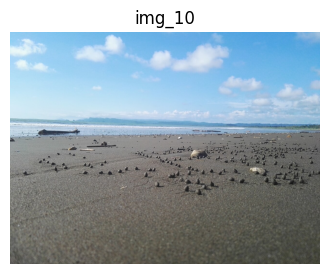

Esperado: Se abstiene: en la foto no hay un producto
Estado: respuesta_generada | JSON de ver(): {'es_producto': True, 'tipo_producto': 'rocas', 'marca': None, 'modelo': None, 'color': None, 'texto_visible': None}
Consulta: rocas
Primera pantalla: ['roca - kit bisagra caída amortig.(ai0001200r) (ai0002600r)', 'roca ai0001200r bisagra asiento wc caida amortiguada, cromo laton', 'roca a801562004 asiento, blanco', 'roca a801511004 dama senso - asiento de repuesto para inodoro, blanco', 'buzifu musgo artificial, 30 unids rocas de musgo, musgo artificial man']
Respuesta: Sí, lo tenemos: roca - kit bisagra caída amortig.(ai0001200r) (ai0002600r) [B00ZPZ93X0], roca ai0001200r bisagra asiento wc caida amortiguada, cromo [B00XE5HOI4], roca a801562004 asiento, blanco [B00C1NLE4K], roca a801511004 dama senso - asiento de repuesto [B00C1NLB4S].

En la foto se ve: rocas. Las fichas son del catálogo histórico de Amazon España (ESCI), no del inventario actual de la tienda.


In [37]:
if not peor.empty:
    cid = peor.index[0]; s = SALIDAS_IMG["M4"][cid]; r = next(x for x in EVAL_IMG if x["id"] == cid)
    plt.figure(figsize=(4, 4)); plt.imshow(IMGS[cid]); plt.axis("off"); plt.title(cid); plt.show()
    print("Esperado:", r["esperado"])
    print("Estado:", s.get("estado"), "| JSON de ver():", s.get("ver_json"))
    print("Consulta:", s.get("consulta_desde_foto"))
    print("Primera pantalla:", [CATALOGO["titulo"][POS[pid]][:70] for pid in s["pantalla"]])
    print("Respuesta:", s["respuesta"])

## 9. Para S14: el modelo más pesado y la latencia por caso

In [38]:
def n_parametros(m):
    return sum(p.numel() for p in m.parameters()) / 1e6

for nombre, m in [("VLM " + VLM_ID, vlm), ("Generador " + GEN_MODEL, gen_model), ("Reranker de M1", mod_ft),
                  ("Embeddings " + MODELO_EMB, st)]:
    print(f"{nombre:<55} {n_parametros(m):>8.0f} M parámetros")
print(f"{'Verificador Qwen/Qwen2.5-3B-Instruct (liberado en la fase B)':<55} ~3.000 M parámetros (ficha del modelo)")
if DEVICE == "cuda":
    print(f"\nPico de VRAM en esta corrida: {torch.cuda.max_memory_allocated() / 1024**3:.2f} GB")
print(f"Latencia por caso con imagen: media {lat_img_m4.mean():.2f}s, de la que ver() es {media(m4['seg_ver']):.2f}s")

VLM Qwen/Qwen2-VL-2B-Instruct                               2209 M parámetros
Generador Qwen/Qwen2.5-1.5B-Instruct                        1544 M parámetros
Reranker de M1                                               118 M parámetros
Embeddings sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2      118 M parámetros
Verificador Qwen/Qwen2.5-3B-Instruct (liberado en la fase B) ~3.000 M parámetros (ficha del modelo)

Pico de VRAM en esta corrida: 9.95 GB
Latencia por caso con imagen: media 3.77s, de la que ver() es 1.72s


## 10. Opcional: ¿vale la pena describir antes de preguntar?


In [39]:
HACER_ABLACION = True   # ver_dos_pasos está en §4.1 y ya corrió en M4.1; aquí solo se aísla su efecto sobre ver()

if HACER_ABLACION:
    fuentes = pd.read_csv(DIR_EVAL / "fuentes_imagenes.csv", dtype=str, encoding="utf-8-sig").fillna("")
    copias = set(fuentes.loc[fuentes["transformacion"].str.startswith("copia de"), "id"])   # img_12 es la foto de img_01
    filas = []
    for r in EVAL_IMG:
        if r["id"] in copias:
            continue
        uno, dos = SALIDAS_IMG["M4"][r["id"]], SALIDAS_IMG["M4.1"][r["id"]]
        filas.append({"id": r["id"], "campos_1_llamada": nota_campos(r, uno), "campos_2_llamadas": nota_campos(r, dos),
                      "seg_1_llamada": uno["latencia"].get("ver"), "seg_2_llamadas": dos["latencia"].get("ver")})
    ABLACION = pd.DataFrame(filas)
    ABLACION.to_csv(DIR_RES / "ablacion_describir_m4.csv", index=False, encoding="utf-8")
    print(ABLACION.mean(numeric_only=True).round(3).to_string())
    ABLACION

campos_1_llamada     0.689
campos_2_llamadas    0.682
seg_1_llamada        1.710
seg_2_llamadas       3.034
